# Quatre TP pour reconstruire un mini-Transformer

**Les Transformers — travaux pratiques** · PyTorch · Tiny Shakespeare, niveau caractère

| Partie | Contenu |
|---|---|
| **TP 1** | Données, vocabulaire, `get_batch`, modèle bigramme, génération |
| **TP 2** | Auto-attention : de la moyenne causale à la tête d'attention |
| **TP 3** | LayerNorm, MLP feed-forward, connexion résiduelle |
| **TP 4** | Mini-GPT complet : entraînement, génération, expériences, bilan |

Le notebook se lit et s'exécute **dans l'ordre**. Chaque TP redéfinit ce dont il a besoin (les classes du TP 4 remplacent celles des TP précédents). Toutes les sorties proviennent d'exécutions sur CPU avec la graine `1337` ; les expériences du TP 4 utilisent un budget réduit (3 000 itérations, 2 graines).

---
# Partie 1 · TP 1 — Données et modèle bigramme

# TP 1 — Du texte brut au premier modèle bigramme

**Les Transformers — travaux pratiques** · *Quatre TP pour reconstruire un mini-Transformer*

---

**Objectif.** Comprendre comment un corpus devient un ensemble de prédictions supervisées, puis entraîner une table qui prédit le caractère suivant.

| Étape | Contenu | Résultat |
|---|---|---|
| 1 | Télécharger et explorer Tiny Shakespeare | texte brut |
| 2 | Construire `encode` et `decode` | entiers |
| 3 | Former contextes, cibles et mini-batchs | tenseurs |
| 4 | Programmer le modèle bigramme | logits |
| 5 | Générer, entraîner, puis comparer | texte généré |

**Fil conducteur** : à chaque étape on vérifie les **formes des tenseurs**, on explique le **rôle mathématique** du code et on teste **une variante**.

**Livrable** : ce notebook exécuté de haut en bas, deux générations (avant et après entraînement) et des réponses courtes aux questions d'interprétation.

## 0. Environnement

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from urllib.request import urlretrieve

torch.manual_seed(1337)            # reproductibilité : tous les résultats ci-dessous sont rejouables
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## Étape 1 — Télécharger et inspecter le corpus

Le modèle n'apprend pas directement Shakespeare : il reçoit une longue suite de caractères. Regardons précisément cette suite.

In [2]:
url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
print(os.path.abspath("input.txt"))

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))
print(text[:1000])

/home/claude/tr/input.txt
1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for b

**À relever** : longueur du corpus, retours à la ligne, ponctuation, majuscules et minuscules.

In [3]:
import string
print(f"Longueur du corpus        : {len(text):,} caractères")
print(f"Retours à la ligne (\\n)   : {text.count(chr(10)):,}  | lignes vides (\\n\\n) : {text.count(chr(10)*2):,}")
print(f"Majuscules / minuscules   : {sum(c.isupper() for c in text):,} / {sum(c.islower() for c in text):,}")
print(f"Ponctuation               : {sum(c in string.punctuation for c in text):,}")
print(f"Espaces                   : {text.count(' '):,}")
print(f"Tous les caractères sont ASCII : {all(ord(c) < 128 for c in text)}")
print("Caractères de ponctuation présents :", "".join(sorted({c for c in text if c in string.punctuation})))

Longueur du corpus        : 1,115,394 caractères
Retours à la ligne (\n)   : 40,000  | lignes vides (\n\n) : 7,221
Majuscules / minuscules   : 88,754 / 762,324
Ponctuation               : 54,397
Espaces                   : 169,892
Tous les caractères sont ASCII : True
Caractères de ponctuation présents : !$&',-.:;?


**Réponses aux questions d'interprétation**

1. **Unité d'un token** : ici, le **caractère** (lettres, espace, retour à la ligne, ponctuation). Le vocabulaire contient 65 caractères distincts, c'est-à-dire aucun « mot » : « First » fait 5 tokens.
2. **`encoding="utf-8"`** : un fichier est une suite d'octets ; `open` doit savoir comment les convertir en caractères. Sans précision, Python utilise l'encodage par défaut de la plateforme (par exemple cp1252 sous Windows), donc le même fichier pourrait donner un texte différent d'une machine à l'autre. Ici le corpus est **100 % ASCII** (vérifié ci-dessus), le résultat serait identique, mais préciser l'encodage rend le notebook portable.
3. **Déjà séparé en exemples ?** Non. C'est **une seule chaîne continue** de 1 115 394 caractères (40 000 lignes ; les 7 221 lignes vides séparent les répliques mais ne sont pas des exemples). Il n'y a ni étiquette ni découpage : c'est nous qui fabriquons les exemples, par fenêtres de `block_size` caractères (étapes 3 et 4).

À relever : 88 754 majuscules pour 762 324 minuscules (les majuscules marquent surtout les noms de locuteurs et les débuts de vers), 54 397 signes de ponctuation (`! $ & ' , - . : ; ?`), 169 892 espaces. Majuscules et minuscules sont des tokens distincts, ce qui contribue aux 65 caractères du vocabulaire.

## Étape 2 — Des caractères aux entiers

PyTorch manipule des nombres. On construit un vocabulaire, puis deux dictionnaires parfaitement inverses.

In [4]:
chars = sorted(list(set(text)))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

message = "hii there"
print(encode(message))
print(decode(encode(message)))
print(decode(encode(message)) == message)

print("\nvocab_size =", vocab_size)
print(repr("".join(chars)))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there
True

vocab_size = 65
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"


In [5]:
# Variante : le test d'aller-retour sur TOUT le corpus, et l'effet d'un vocabulaire non trié
assert decode(encode(text)) == text
print("aller-retour sur les", f"{len(text):,}", "caractères : OK")

# sans tri, l'ordre d'un set de str peut changer d'un processus Python à l'autre (hachage aléatoire des chaînes)
import subprocess, sys
sortie = [subprocess.run([sys.executable, "-c", "t=open('input.txt').read(); print(list(set(t))[:5])"],
                         capture_output=True, text=True).stdout.strip() for _ in range(3)]
print("list(set(text))[:5] dans 3 processus différents :")
for s in sortie:
    print("  ", s)

aller-retour sur les 1,115,394 caractères : OK
list(set(text))[:5] dans 3 processus différents :
   ['J', 'p', 'D', 'Q', 'G']
   ['K', 'r', 'Q', 'A', 'G']
   ['Z', 'F', 'C', 'l', 'I']


**Réponses aux questions d'interprétation**

- **Pourquoi trier `chars` ?** Un `set` n'a pas d'ordre garanti : l'ordre d'itération de chaînes change d'un processus Python à l'autre (hachage aléatoire), comme le montre la sortie ci-dessus (trois processus, trois ordres). Sans tri, un même caractère recevrait **un indice différent à chaque exécution** : des poids ou embeddings sauvegardés n'auraient plus de sens. Trié, le vocabulaire est **déterministe** (`'\n'` = 0, `' '` = 1, `'!'` = 2, …, `'h'` = 46).
- **Que garantit `decode(encode(message)) == message` ?** Que `stoi` et `itos` sont deux **bijections inverses** : la tokenisation est **sans perte**. Nous avons étendu le test à tout le corpus (aller-retour exact sur 1 115 394 caractères).
- **Limite du test** : il prouve la réversibilité *pour les caractères du vocabulaire* ; un caractère absent (par exemple `é` ou `{`) lèverait une `KeyError` dans `encode`.

## Étape 3 — Fabriquer les prédictions attendues

Une même séquence de longueur $T+1$ fournit une entrée `x` et une cible `y` décalée d'une position : chaque token doit prédire le suivant.

In [6]:
data = torch.tensor(encode(text), dtype=torch.long)

n_train = int(0.9 * len(data))
train_data = data[:n_train]
val_data = data[n_train:]

block_size = 8
x = train_data[:block_size]
y = train_data[1:block_size + 1]

for t in range(block_size):
    context = x[:t + 1]
    target = y[t]
    print(context, "->", target)

print("\nformes :", data.shape, train_data.shape, val_data.shape, "| x", x.shape, "y", y.shape)
print("x =", repr(decode(x.tolist())), "| y =", repr(decode(y.tolist())))
t = 3
print(f"\nt = {t} : contexte = {repr(decode(x[:t+1].tolist()))}, cible = {repr(decode([y[t].item()]))}")

tensor([18]) -> tensor(47)
tensor([18, 47]) -> tensor(56)
tensor([18, 47, 56]) -> tensor(57)
tensor([18, 47, 56, 57]) -> tensor(58)
tensor([18, 47, 56, 57, 58]) -> tensor(1)
tensor([18, 47, 56, 57, 58,  1]) -> tensor(15)
tensor([18, 47, 56, 57, 58,  1, 15]) -> tensor(47)
tensor([18, 47, 56, 57, 58,  1, 15, 47]) -> tensor(58)

formes : torch.Size([1115394]) torch.Size([1003854]) torch.Size([111540]) | x torch.Size([8]) y torch.Size([8])
x = 'First Ci' | y = 'irst Cit'

t = 3 : contexte = 'Firs', cible = 't'


**Réponses aux questions d'interprétation**

1. **Combien de prédictions ?** Un bloc de `T + 1 = 9` caractères fournit **`T = 8` prédictions**, une par position, avec des contextes de longueur 1 à 8. C'est le gain du décalage : un seul bloc donne 8 exemples d'apprentissage.
2. **Pourquoi ne pas mélanger train et validation ?** La validation doit mesurer la **généralisation à du texte jamais vu**. Les fenêtres se recouvrent (décalées d'un caractère) : si on mélangeait, presque chaque fenêtre de validation aurait des voisines quasi identiques dans le train, et la loss de validation serait artificiellement basse (fuite). On coupe donc en **deux blocs contigus** : 90 % pour le train (1 003 854 caractères) et 10 % pour la validation (111 540), qui contient d'autres scènes.
3. **Pour `t = 3`** : contexte = `x[:4]` = `[18, 47, 56, 57]` = **`'Firs'`** ; cible = `y[3]` = 58 = **`'t'`**. Le modèle doit prédire `t` sachant `Firs`.

## Étape 4 — Échantillonner un mini-batch

Un mini-batch regroupe $B$ séquences indépendantes de longueur $T$ : toutes les prédictions sont calculées en parallèle.

In [7]:
batch_size = 4
block_size = 8

def get_batch(split):
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size, (batch_size,)
    )
    x = torch.stack([
        source[i : i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in starts
    ])
    return x, y

xb, yb = get_batch("train")
print(xb.shape, yb.shape)
print("xb =\n", xb); print("yb =\n", yb)
print("\nVérification du décalage : yb[:, :-1] == xb[:, 1:] ->", bool((yb[:, :-1] == xb[:, 1:]).all()))
for b in range(batch_size):
    print(f"ligne {b} : {repr(decode(xb[b].tolist()))} -> {repr(decode(yb[b].tolist()))}")

torch.Size([4, 8]) torch.Size([4, 8])
xb =
 tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
yb =
 tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])

Vérification du décalage : yb[:, :-1] == xb[:, 1:] -> True
ligne 0 : "Let's he" -> "et's hea"
ligne 1 : 'for that' -> 'or that '
ligne 2 : 'nt that ' -> 't that h'
ligne 3 : 'MEO:\nI p' -> 'EO:\nI pa'


In [8]:
# Variantes : B = 32 puis T = 64
for B, T in [(4, 8), (32, 8), (4, 64)]:
    batch_size, block_size = B, T
    xb_, yb_ = get_batch("train")
    print(f"B = {B:2d}, T = {T:2d} -> xb {tuple(xb_.shape)} : {xb_.numel():5d} tokens, soit {yb_.numel():5d} prédictions par batch")
batch_size, block_size = 4, 8        # retour aux valeurs de départ

B =  4, T =  8 -> xb (4, 8) :    32 tokens, soit    32 prédictions par batch
B = 32, T =  8 -> xb (32, 8) :   256 tokens, soit   256 prédictions par batch
B =  4, T = 64 -> xb (4, 64) :   256 tokens, soit   256 prédictions par batch


**Réponses aux questions d'interprétation**

1. **Pourquoi retirer `block_size` à la borne de tirage ?** `torch.randint(high, …)` exclut `high`. La séquence cible va jusqu'à `i + block_size + 1` (exclu) : il faut `i + block_size + 1 ≤ len(source)`, donc `i ≤ len(source) − block_size − 1`, ce que garantit `high = len(source) − block_size`. Sans ce retrait, un tirage près de la fin donnerait une cible `y` **plus courte** que `x`, et `torch.stack` échouerait.
2. **Que change `B = 32` ?** Les formes passent de `(4, 8)` à `(32, 8)` : **256 prédictions par batch** au lieu de 32 (voir la cellule des variantes). Le gradient est moyenné sur plus d'exemples (moins bruité) au prix de plus de calcul et de mémoire par pas.
3. **Que change `T = 64` ?** Chaque séquence fournit 64 prédictions et le contexte maximal passe à 64 caractères : `(4, 64)` = 256 tokens, comme `(32, 8)`. **Mais le bigramme n'utilise que le dernier caractère**, donc la longueur du contexte n'apporte ici rien d'autre qu'un plus grand nombre de prédictions ; elle prendra tout son sens avec l'attention (TP 2), où le coût croît en $T^2$.

## Étape 5 — Une table produit les logits

Chaque caractère choisit directement une ligne contenant un score pour chacun des $C$ caractères possibles.

In [9]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, vocab_size
        )

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)
        # idx: (B,T) -> logits: (B, T, C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx)
            logits = logits[:, -1, :]                     # dernier pas de temps : (B, C)
            probs = F.softmax(logits, dim=-1)             # (B, C)
            idx_next = torch.multinomial(
                probs, num_samples=1
            )                                             # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)       # (B, T+1)
        return idx

model = BigramLanguageModel(vocab_size)
logits, loss = model(xb, yb)
print("logits :", logits.shape, "| loss :", loss.item())
print("nombre de paramètres :", sum(p.numel() for p in model.parameters()), "= C x C =", vocab_size, "x", vocab_size)
print("loss d'un tirage uniforme ln(C) :", torch.log(torch.tensor(float(vocab_size))).item())

logits3, _ = model(xb)                       # sans cibles : on garde la forme (B, T, C)
print("sans cibles :", logits3.shape)

logits : torch.Size([32, 65]) | loss : 4.810960292816162
nombre de paramètres : 4225 = C x C = 65 x 65
loss d'un tirage uniforme ln(C) : 4.174387454986572
sans cibles : torch.Size([4, 8, 65])


**Réponses aux questions d'interprétation**

**Pourquoi $C \times C$ ?** La table a **une ligne par caractère courant** (C = 65) et **une colonne par caractère suivant possible** (C = 65) : la ligne `i` contient les 65 scores du prochain caractère sachant uniquement que le caractère courant est `i`. D'où 65 × 65 = **4 225 paramètres**, ce que confirme le comptage.

**Formes** : `idx` `(B, T)` → `logits` `(B, T, C)` ; avec cibles, on aplatit en `(B·T, C)` pour `cross_entropy`.

**Loss initiale** : 4,81 sur ce batch (4,73 en moyenne sur 200 batchs) contre ln 65 = 4,17 pour un tirage uniforme. Elle est plus haute parce que l'embedding est initialisé en $\mathcal N(0, 1)$ : les logits ne sont pas égaux, et le modèle est un peu *plus sûr de lui que de raison*.

**Où retrouvera-t-on $d_{emb}$ et `lm_head` au TP 4 ?** Ici, dimension d'embedding = C : la ligne de la table *est* directement le vecteur de logits. Au TP 4, ces deux rôles se séparent : `token_embedding_table` devient une matrice `(C_vocab × n_embd)` (identité du caractère), les blocs travaillent en dimension `n_embd`, et **`lm_head = nn.Linear(n_embd, vocab_size)`** (matrice `n_embd × C_vocab`) ré-projette vers les C logits. La table bigramme est le cas particulier où `n_embd = C` et où il n'y a ni blocs ni `lm_head`.

## Étapes 6 et 7 — Générer, puis apprendre

On génère une première fois avec les **poids aléatoires**, on entraîne la table, puis on relance **exactement la même procédure** pour observer ce qui a changé.

In [10]:
# Mesure fiable : moyenne de la loss sur 200 mini-batchs (la loss d'un seul batch est trop bruitée)
batch_size, block_size = 32, 8
@torch.no_grad()
def estimate_loss(model, iters=200):
    out = {}
    for split in ["train", "val"]:
        out[split] = torch.stack([model(*get_batch(split))[1] for _ in range(iters)]).mean().item()
    return out

def generer(model, n=300, seed=0):
    torch.manual_seed(seed)                    # même graine -> les différences viennent des poids
    ctx = torch.zeros((1, 1), dtype=torch.long)            # indice 0 = '\n'
    return decode(model.generate(ctx, max_new_tokens=n)[0].tolist())

torch.manual_seed(1337)
model = BigramLanguageModel(vocab_size)
print("loss moyenne AVANT entraînement :", estimate_loss(model))
print("\n=== Génération AVANT entraînement ===")
print(generer(model))

loss moyenne AVANT entraînement : {'train': 4.730469226837158, 'val': 4.724065780639648}

=== Génération AVANT entraînement ===

t3ZxjmhObjxhRwLs$lgUW?oHEa
?egma!Uv&ydfIgAcsvSBUMyFoiy$By$z-Pnt;
kVrM z&?juDJP!U?EHevC!BTH3firdc;slga-w3KylorWwXxMb
JARSA:COLqKU,l:r&DH-Pmv$fxfyHAHMkpwPyJmIfFBi'MV&iMO$EotgHAc!BScLj'
&yuzyFFu!!Bj.SVqHI&yepxfSpmP$
-wi$HATW-QQnxrlvKNfMjxfBojq?dhfOIomOwiAmuzK'PIRpJAER,nm3F.Kib?bSxy;L&AToERSqV; v!BNCmhF


In [11]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-3
)

batch_size = 4
for step in range(100):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print("loss du dernier batch :", loss.item())

batch_size = 32
print("loss moyenne après 100 étapes :", estimate_loss(model))
print("\n=== Génération APRÈS 100 étapes ===")
print(generer(model))

loss du dernier batch : 4.693065643310547


loss moyenne après 100 étapes : {'train': 4.653468132019043, 'val': 4.65077018737793}

=== Génération APRÈS 100 étapes ===

t3ZxjmhObjxhRwLs$lgUW?oHEa -egma!Uv&ydfIgAcstSBUMyFoiy$By$z-Pnt;
kVrM z&?juDJP!U?EHevC!BTH3firdc;slga-w3KylorWwXxMb
JARSA:COLqKU,l:r&DH-Pmv$fxfyHAHMkpwPyJmIfFBi'MV&iMO$EotgHAc!BScLj'
&yuzyFFu!!Bj.SVqHI&yepxfSpmP$
-wi$HATW-QQnxrlvKNfMjxfBojq?dhfOIomOwiAmuzK'PIRpJAER,nm3F.Kib?bSxy;L&AToERSqV; v!BNCmhF


In [12]:
# On poursuit jusqu'à 1 000 étapes au total
batch_size = 4
for step in range(900):
    xb, yb = get_batch("train")
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
batch_size = 32
print("loss moyenne après 1 000 étapes :", estimate_loss(model))
print("\n=== Génération APRÈS 1 000 étapes ===")
print(generer(model))

loss moyenne après 1 000 étapes : {'train': 4.053050518035889, 'val': 4.047021865844727}

=== Génération APRÈS 1 000 étapes ===

t3ZxjmhObjxhRwLs$lgUW?oHEa -egma!Uv&ydfIgAcstSBUMyFoiy$By$z-Pnt;
kVrM z&?juDJP!U?EHevC!BTH3fird Cslga-w3KylorWwXxMb
JARSA:COLqKU,l:r&DH-Pmv$fxfy!AHMkpwPyJm;fFBi'MV&iMO$Eott,SP!BScLj'
sC-zy,Fu!!Bj.SVqHI&yepxfSpmP$
-wi$HATW-QQnhrlvKNfMjxzPH3q?dgflIomOwiAmuzK'TIRpJAER,nm3F.Kib?bSxy;L&AToERSqV; v!BNCmhF


### Aller plus loin : jusqu'où une simple table peut-elle descendre ?

Le meilleur modèle bigramme possible est la table de fréquences empiriques `P(suivant | courant)`. On la calcule directement par comptage : c'est le **plancher** qu'une table $C \times C$ ne peut pas franchir.

In [13]:
# Plancher théorique d'un bigramme : entropie conditionnelle empirique (comptage direct sur le train)
counts = torch.zeros(vocab_size, vocab_size)
for a, b in zip(train_data[:-1], train_data[1:]):
    counts[a, b] += 1
P = (counts + 1) / (counts + 1).sum(1, keepdim=True)          # lissage de Laplace

def nll_table(split_data):
    return -torch.log(P[split_data[:-1], split_data[1:]]).mean().item()

print(f"table de comptage : loss train = {nll_table(train_data):.3f} | loss val = {nll_table(val_data):.3f}")

# un nouveau modèle, entraîné plus longtemps avec un pas plus grand
torch.manual_seed(1337)
m2 = BigramLanguageModel(vocab_size)
opt2 = torch.optim.AdamW(m2.parameters(), lr=1e-2)
batch_size = 32
for step in range(3000):
    xb, yb = get_batch("train")
    _, loss = m2(xb, yb)
    opt2.zero_grad(set_to_none=True); loss.backward(); opt2.step()
print("modèle entraîné 3 000 étapes (lr 1e-2) :", {k: round(v, 3) for k, v in estimate_loss(m2).items()})

# la ligne apprise pour 'q' ressemble-t-elle à la table de fréquences ?
q = stoi["q"]
appris = F.softmax(m2.token_embedding_table.weight[q], dim=-1)
for nom, p in [("apprise ", appris), ("comptée ", P[q])]:
    top = torch.topk(p, 3)
    print(f"après 'q', {nom}:", [(repr(itos[i.item()]), round(v.item(), 3)) for v, i in zip(top.values, top.indices)])
batch_size = 4

print("\n=== Génération avec la table convergée (3 000 étapes, lr 1e-2) ===")
print(generer(m2, n=400))

table de comptage : loss train = 2.455 | loss val = 2.482


modèle entraîné 3 000 étapes (lr 1e-2) : {'train': 2.472, 'val': 2.489}
après 'q', apprise : [("'u'", 0.951), ("'-'", 0.007), ("','", 0.003)]
après 'q', comptée : [("'u'", 0.898), ("'d'", 0.002), ("'e'", 0.002)]

=== Génération avec la table convergée (3 000 étapes, lr 1e-2) ===

th rem?
We hexpselteredoca meaman youd INAlste grecofue y h fotherere hath thio berelisBeanongicost.
tho y we w ke RY hees idarthotr nd; my f tsoo we w y mer ai'd I oervothad te chan s uzed
I s h.S:
HINVeprf plan

O:
HAToonond ssay eint odeld fleome inou inkee he t,
As t inobe y tonesthast st hayowanea.
sth d wheseam l limy IftitheD&vershs m, il
I or ore vios ber emyou woofut d s tlr wan noou lpin


**Bilan du TP 1 — réponses**

**1. Pourquoi ne garder que le dernier pas de temps pendant la génération ?** Le modèle renvoie des logits `(B, T, C)` : une prédiction **après chaque position**. En génération on cherche le caractère qui suit la séquence *entière*, donc la prédiction de la **dernière position** (`logits[:, -1, :]`, forme `(B, C)`) ; les autres concernent des caractères déjà connus. Dans le bigramme, la dernière position est de toute façon la seule utile (les précédentes ne sont pas lues) ; avec l'attention, cette dernière ligne résumera tout le contexte.

**2. Pourquoi aplatir $B \times T$ pendant la loss ?** `F.cross_entropy` attend des logits `(N, C)` et des cibles `(N,)`. Les $B \cdot T$ prédictions sont indépendantes les unes des autres : chacune est un problème de classification à C classes, et la loss est leur moyenne.

**3. Comparaison des pertes et des textes** (loss moyenne sur 200 batchs ; avec `lr = 1e-3` et batch de 4) :

| Moment | loss train | loss val | Texte généré |
|---|---|---|---|
| Avant entraînement | 4,730 | 4,724 | caractères au hasard, sans structure |
| Après 100 étapes | 4,653 | 4,651 | **presque identique** au précédent |
| Après 1 000 étapes | 4,053 | 4,047 | encore du bruit : seules quelques lettres changent |
| Table convergée (3 000 étapes, `lr = 1e-2`, batch 32) | 2,472 | 2,489 | **fragments de mots** (`We`, `th`, `youd`), espaces et retours à la ligne plausibles |

- La même graine est utilisée pour chaque génération : les textes se ressemblent tant que la distribution apprise reste proche de l'uniforme, ce qui illustre que **100 étapes à `lr = 1e-3` modifient très peu la table** (loss −0,08 seulement).
- **Le plancher d'une table** : le bigramme optimal (comptage direct) atteint **2,455 / 2,482** (train / val). Le modèle à 3 000 étapes (2,472 / 2,489) s'en approche : l'entraînement n'a fait que **rapprocher chaque ligne de la table de la distribution empirique du caractère suivant** (après `q`, la table apprise donne `u` à 95 %, le comptage 90 %).
- **Limite** : une loss de 2,46, c'est mieux que 4,17 mais le texte reste du bruit « presque anglais ». Un caractère ne peut pas tenir compte du contexte, ce qui motive l'attention (TP 2).

---
# Partie 2 · TP 2 — Auto-attention

# TP 2 — Construire l'auto-attention pas à pas

**Les Transformers — travaux pratiques** · *Quatre TP pour reconstruire un mini-Transformer*

---

**Objectif.** Partir d'une simple **moyenne des tokens précédents** et arriver à une **tête d'attention qui apprend elle-même** quels tokens doivent contribuer.

`boucles (moyenne causale)` → `produit matriciel (poids fixes)` → `masque + softmax (poids normalisés)` → `self-attention (poids appris)`

**Invariant à suivre** : une ligne de poids contient la contribution des tokens passés au calcul du token courant, et **sa somme vaut toujours 1**.

**Livrable** : les quatre versions, les tests `torch.allclose`, la matrice `wei[0]`, et une explication des formes $B$, $T$, $C$, $d_h$.

## 0. Environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## Étape 1 — Agréger par produit matriciel

Avant l'attention, vérifions qu'**une ligne de matrice peut choisir et pondérer plusieurs vecteurs** : $c_t = \sum_i a_{t,i}\, b_i$.

In [2]:
torch.manual_seed(42)

a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)

b = torch.randint(0, 10, (3, 2)).float()
c = a @ b

print(a)
print(b)
print(c)

tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [3]:
# Vérification du calcul « à la main » de c_2 (3e ligne : moyenne des trois vecteurs b)
print("c[2]                  =", c[2])
print("moyenne à la main      =", b.mean(dim=0))
print("somme de chaque ligne de a =", a.sum(dim=1))

c[2]                  = tensor([4.6667, 5.3333])
moyenne à la main      = tensor([4.6667, 5.3333])
somme de chaque ligne de a = tensor([1., 1., 1.])


**Réponses aux questions d'interprétation**

**Calcul sans Python.** $a$ est la matrice triangulaire dont chaque ligne est normalisée : sa 3ᵉ ligne vaut $(1/3,\,1/3,\,1/3)$. Donc
$$c_2 = \tfrac13(b_0 + b_1 + b_2) = \tfrac13\big([2,7] + [6,4] + [6,5]\big) = \tfrac13[14,\,16] = [4{,}667,\; 5{,}333],$$
ce que confirme la cellule ci-dessus (`c[2]` = moyenne à la main). De même $c_0 = b_0 = [2,7]$ et $c_1 = \tfrac12(b_0+b_1) = [4;\,5{,}5]$.

**Pourquoi chaque ligne de $a$ somme à 1 ?** On a divisé chaque ligne de `tril(ones)` par sa propre somme (`keepdim=True`). Une ligne de poids qui somme à 1 est une **moyenne pondérée** (combinaison convexe) : la sortie reste à la même échelle que les entrées. Sans cette normalisation, la sortie $c_t$ grossirait avec $t$ (somme de $t+1$ vecteurs au lieu de leur moyenne).

## Étape 2 — Moyenner uniquement le passé (version 1 : boucles)

Pour chaque batch $b$ et chaque instant $t$, on construit la moyenne de tous les tokens visibles jusqu'à $t$. **Aucune position ne doit accéder au futur.**

In [4]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

xbow = torch.zeros((B, T, C))
for b in range(B):
    for t in range(T):
        xprev = x[b, :t + 1]            # forme (t+1, C)
        xbow[b, t] = torch.mean(xprev, dim=0)

print("x :", x.shape, "| xbow :", xbow.shape)
for t in (0, 3, 7):
    print(f"t = {t} : xprev a la forme {tuple(x[0, :t + 1].shape)}")
print("\nx[0] =\n", x[0])
print("xbow[0] =\n", xbow[0])
print("xbow[0, 0] == x[0, 0] ? ->", torch.allclose(xbow[0, 0], x[0, 0]))

x : torch.Size([4, 8, 2]) | xbow : torch.Size([4, 8, 2])
t = 0 : xprev a la forme (1, 2)
t = 3 : xprev a la forme (4, 2)
t = 7 : xprev a la forme (8, 2)

x[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
xbow[0] =
 tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])
xbow[0, 0] == x[0, 0] ? -> True


**Réponses aux questions d'interprétation**

- **Formes de `xprev`** : $(1, C)$ pour $t=0$, $(4, C)$ pour $t=3$ et $(8, C)$ pour $t=7$, avec $C=2$ ici (cf. sortie). Elle a `t + 1` lignes : les positions $0,\dots,t$, **jamais** les suivantes, d'où la causalité.
- **Pourquoi `dim=0` ?** `xprev` est de forme `(t+1, C)` : la dimension 0 est l'axe du **temps**. On veut moyenner *les tokens* (les `t+1` lignes) en gardant les `C` canaux : le résultat est un vecteur de dimension `C`. Moyenner sur `dim=1` mélangerait les canaux d'un même token, ce qui n'a pas de sens.
- Contrôles : `xbow[0, 0] == x[0, 0]` (le premier token n'a que lui-même pour contexte), et `xbow[0, 1]` est bien la moyenne des deux premières lignes de `x[0]`.

## Étapes 3 et 4 — Vectoriser (versions 2 et 3)

La matrice triangulaire reproduit la moyenne causale ; le **masque $-\infty$ suivi de softmax** produit exactement les mêmes poids.

In [5]:
# Version 2 : matrice triangulaire normalisée
wei = torch.tril(torch.ones(T, T))
wei = wei / wei.sum(1, keepdim=True)

xbow2 = wei @ x
print(torch.allclose(
    xbow, xbow2, atol=1e-6
))

True


In [6]:
# Version 3 : masque -inf puis softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros((T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

xbow3 = wei @ x
print(torch.allclose(
    xbow, xbow3, atol=1e-6
))

print("\nwei (versions 2 et 3 identiques) :")
print(wei)
print("somme de chaque ligne :", wei.sum(1))
print("poids vers le futur (triangle supérieur) tous nuls :", bool((wei.triu(1) == 0).all()))

True

wei (versions 2 et 3 identiques) :
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])
somme de chaque ligne : tensor([1., 1., 1., 1., 1., 1., 1., 1.])
poids vers le futur (triangle supérieur) tous nuls : True


In [7]:
# Variante : la matrice (T,T) se diffuse sur le batch ; softmax d'une ligne contenant -inf
print("formes :", wei.shape, "@", x.shape, "->", (wei @ x).shape)
z = torch.tensor([0.0, 1.0, float('-inf'), float('-inf')])
print("softmax([0, 1, -inf, -inf]) =", F.softmax(z, dim=-1))

formes : torch.Size([8, 8]) @ torch.Size([4, 8, 2]) -> torch.Size([4, 8, 2])
softmax([0, 1, -inf, -inf]) = tensor([0.2689, 0.7311, 0.0000, 0.0000])


**Réponses aux questions d'interprétation**

**Pourquoi `wei @ x` fonctionne-t-il ?** `wei` a la forme `(T, T)` et `x` la forme `(B, T, C)`. L'opérateur `@` de PyTorch **diffuse** (broadcast) la matrice 2-D sur la dimension de batch : il calcule `(T,T) @ (T,C)` pour chaque $b$, ce qui donne `(B, T, C)`. Les mêmes poids sont donc appliqués à tous les exemples (cas de la moyenne, où les poids ne dépendent pas des données). Pour la self-attention, `wei` aura déjà la forme `(B, T, T)` : un produit matriciel par batch.

**Que devient Softmax aux emplacements $-\infty$ ?** $e^{-\infty} = 0$ : ces positions reçoivent un **poids exactement nul** et les poids restants sont renormalisés pour sommer à 1 (cf. `softmax([0, 1, -inf, -inf]) = [0,269 ; 0,731 ; 0 ; 0]`). C'est ce qui bloque l'accès au futur. On met $-\infty$ plutôt que 0 *avant* le softmax, car $e^0 = 1$ donnerait un poids positif au futur. Remarque : si toute une ligne valait $-\infty$, on obtiendrait `NaN` ; dans l'attention causale, la diagonale est toujours visible, donc ce cas n'arrive pas.

Les versions 1 (boucles), 2 (matrice) et 3 (masque + softmax) coïncident (`allclose` = `True`) : le softmax d'un score nul constant sur les positions visibles redonne $1/(t+1)$.

## Étape 5 — Calculer des poids d'attention (version 4 : poids appris)

Les poids ne sont plus fixés à $1/(t+1)$ : ils proviennent de la **compatibilité entre queries et keys**.

In [8]:
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

key   = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)                      # (B,T,16)
q = query(x)                    # (B,T,16)
wei = q @ k.transpose(-2, -1)   # (B,T,T)
wei = wei * head_size**-0.5     # mise a l'echelle
tril = torch.tril(torch.ones(T, T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v                   # (B,T,16)

print("x   :", tuple(x.shape),  " (B, T, C)")
print("k, q, v :", tuple(k.shape), " (B, T, d_h)   | k^T :", tuple(k.transpose(-2, -1).shape), " (B, d_h, T)")
print("wei :", tuple(wei.shape), " (B, T, T)")
print("out :", tuple(out.shape), " (B, T, d_h)")

x   : (4, 8, 32)  (B, T, C)
k, q, v : (4, 8, 16)  (B, T, d_h)   | k^T : (4, 16, 8)  (B, d_h, T)
wei : (4, 8, 8)  (B, T, T)
out : (4, 8, 16)  (B, T, d_h)


In [9]:
# La matrice wei[0] et les trois contrôles de l'invariant
print("wei[0] =")
print(wei[0])
print("\nsomme des lignes de wei           =", wei.sum(-1)[0])
print("somme des lignes = 1 pour tout (b,t) :", torch.allclose(wei.sum(-1), torch.ones(B, T)))
print("aucun poids vers le futur             :", bool((wei.masked_fill(tril == 1, 0) == 0).all()))
print("forme finale (B, T, d_h) attendue (4, 8, 16) :", tuple(out.shape) == (4, 8, 16))

wei[0] =
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3966, 0.6034, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3069, 0.2892, 0.4039, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3233, 0.2175, 0.2443, 0.2149, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1479, 0.2034, 0.1663, 0.1455, 0.3369, 0.0000, 0.0000, 0.0000],
        [0.1259, 0.2490, 0.1324, 0.1062, 0.3141, 0.0724, 0.0000, 0.0000],
        [0.1598, 0.1990, 0.1140, 0.1125, 0.1418, 0.1669, 0.1061, 0.0000],
        [0.0845, 0.1197, 0.1078, 0.1537, 0.1086, 0.1146, 0.1558, 0.1553]],
       grad_fn=<SelectBackward0>)

somme des lignes de wei           = tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000],
       grad_fn=<SelectBackward0>)
somme des lignes = 1 pour tout (b,t) : True
aucun poids vers le futur             : True
forme finale (B, T, d_h) attendue (4, 8, 16) : True


In [10]:
# Variante : les poids sont-ils appris/dépendants des données ? Ils diffèrent d'un batch à l'autre, contrairement à la moyenne causale
uniforme = torch.tril(torch.ones(T, T)); uniforme = uniforme / uniforme.sum(1, keepdim=True)
print("la dernière ligne (t = 7) de wei[0]   :", wei[0, -1])
print("la même ligne pour la moyenne causale :", uniforme[-1])
print("wei[0] == wei[1] ?", torch.allclose(wei[0], wei[1]), "| écart moyen |wei[0] - uniforme| =", (wei[0] - uniforme).abs().mean().item())

la dernière ligne (t = 7) de wei[0]   : tensor([0.0845, 0.1197, 0.1078, 0.1537, 0.1086, 0.1146, 0.1558, 0.1553],
       grad_fn=<SelectBackward0>)
la même ligne pour la moyenne causale : tensor([0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250])
wei[0] == wei[1] ? False | écart moyen |wei[0] - uniforme| = 0.025129063054919243


**Réponses aux questions d'interprétation**

**Quelle ligne correspond au dernier token ?** La **dernière ligne**, `wei[0, -1]` ($t = 7$). Elle donne la répartition de l'attention du dernier token sur les 8 positions (de 0 à 7, lui compris) ; c'est la seule ligne qui voit tout le contexte.

**Constats sur `wei[0]`** (sortie ci-dessus) : triangulaire inférieure, lignes de somme 1, rien vers le futur. La ligne 1 vaut `[0,397 ; 0,603]`, ni `[0,5 ; 0,5]` ni une valeur fixée : **le poids dépend des tokens**, contrairement à la moyenne causale. La dernière ligne reste proche de l'uniforme (de 0,085 à 0,156 contre 0,125) : avec des poids initialisés au hasard, les scores $qk^\top$ sont petits, donc le softmax est presque plat. L'écart moyen à la matrice uniforme est de seulement 0,025 ; il grandira avec l'apprentissage. `wei[0]` ≠ `wei[1]` : les poids changent d'un exemple à l'autre.

**Pourquoi la sortie mélange-t-elle $v$ et pas $k$ ?** Les rôles sont séparés : la **query** dit ce que le token cherche, la **key** dit ce qu'il offre comme *adresse* (elle sert à calculer la compatibilité, donc les poids), la **value** est le *contenu* effectivement transmis. Si l'on mélangeait $k$, on transmettrait une représentation optimisée pour être comparée, pas pour être lue ; et un token ne pourrait pas être « facile à trouver » sans transmettre la même information. Avec trois projections, ce qui est cherché, ce qui sert d'étiquette et ce qui est transmis sont appris indépendamment. Forme de la sortie : `(B, T, d_h)` = `(4, 8, 16)`.

## Étape 6 — Stabiliser le softmax

La variance du produit scalaire augmente avec $d_h$ : $\mathrm{Var}(qk^\top) \approx d_h$. Diviser par $\sqrt{d_h}$ garde les scores dans une zone où le softmax reste informatif.

In [11]:
torch.manual_seed(1337)
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)

raw = q @ k.transpose(-2, -1)
scaled = raw * head_size**-0.5

print(raw.var(), scaled.var())

z = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
print(torch.softmax(z, dim=-1))
print(torch.softmax(z * 8, dim=-1))

tensor(18.4436) tensor(1.1527)
tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


In [12]:
# Variante : effet de d_h et conséquence sur les poids (entropie moyenne des lignes du softmax, sans masque)
def entropie_moyenne(wei):
    p = F.softmax(wei, dim=-1)
    return -(p * torch.log(p + 1e-12)).sum(-1).mean().item()

print(f"{'d_h':>5} | {'Var brute':>10} | {'Var mise à l échelle':>20} | {'entropie sans échelle':>22} | {'entropie avec échelle':>22}   (uniforme = ln 8 = {torch.log(torch.tensor(8.)).item():.3f})")
for dh in (4, 16, 64, 256):
    kk, qq = torch.randn(4, 8, dh), torch.randn(4, 8, dh)
    r = qq @ kk.transpose(-2, -1); s = r * dh**-0.5
    print(f"{dh:5d} | {r.var().item():10.2f} | {s.var().item():20.2f} | {entropie_moyenne(r):22.3f} | {entropie_moyenne(s):22.3f}")

  d_h |  Var brute | Var mise à l échelle |  entropie sans échelle |  entropie avec échelle   (uniforme = ln 8 = 2.079)
    4 |       3.46 |                 0.87 |                  1.355 |                  1.781
   16 |      14.99 |                 0.94 |                  0.770 |                  1.754
   64 |      62.35 |                 0.97 |                  0.292 |                  1.728
  256 |     292.58 |                 1.14 |                  0.158 |                  1.698


**Bilan du TP 2 — réponses**

**Variance.** Sans échelle, la variance de $q k^\top$ vaut 18,44 pour $d_h = 16$ ; avec la division par $\sqrt{d_h}$, elle tombe à 1,15 (≈ 1, comme celle des entrées). La table de la variante montre que la variance brute croît **proportionnellement à $d_h$** (3,5 ; 15,0 ; 62,4 ; 292,6 pour $d_h = 4, 16, 64, 256$) tandis que la version mise à l'échelle reste ≈ 1 (0,87 à 1,14). Raison : le produit scalaire est une somme de $d_h$ termes indépendants de variance ≈ 1.

**Effet sur le softmax.** Multiplier des scores par un grand facteur rend le softmax **pointu**, presque un one-hot. Avec $z=[0,1;\,-0,2;\,0,3;\,-0,2;\,0,5]$ : `[0,19 ; 0,14 ; 0,24 ; 0,14 ; 0,29]` (diffus), mais avec $8z$ : `[0,03 ; 0,003 ; 0,16 ; 0,003 ; 0,80]`, soit 80 % sur un seul élément. Le tableau d'entropie le confirme : sans échelle, l'entropie moyenne de l'attention s'effondre quand $d_h$ augmente (1,36 → 0,16 nat pour $d_h$ de 4 à 256, uniforme = 2,08), alors qu'elle reste entre 1,70 et 1,78 avec l'échelle.

**Conséquence.** Un softmax saturé est quasi-constant par morceaux : ses gradients sont presque nuls (un token reçoit tout le poids, les autres rien) et l'apprentissage devient lent ou instable, surtout au début ; la division par $\sqrt{d_h}$ garde le softmax dans une zone où il reste sensible aux scores.

**Bilan du TP 2.**

| Version | Poids | Causalité | Test |
|---|---|---|---|
| 1. boucles | $1/(t+1)$ | `x[b, :t+1]` | référence |
| 2. `tril` normalisé @ x | $1/(t+1)$ | triangulaire | `allclose` = True |
| 3. `masked_fill(-inf)` + softmax | $1/(t+1)$ | masque | `allclose` = True |
| 4. self-attention | **appris** : softmax$(qk^\top/\sqrt{d_h})$ | masque | lignes de somme 1, pas de futur |

Formes à retenir : $x$ `(B,T,C)` → $q,k,v$ `(B,T,d_h)` → `wei` `(B,T,T)` → `out` `(B,T,d_h)`. La version 4 garde la mécanique de la version 3 (masque + softmax + `@`) : seuls les **scores** changent, de « tous égaux » à « $q\cdot k$ ».

### Récapitulatif : les quatre versions

In [13]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)
v1 = torch.zeros(B, T, C)
for b in range(B):
    for t in range(T):
        v1[b, t] = x[b, :t + 1].mean(dim=0)
w2 = torch.tril(torch.ones(T, T)); w2 = w2 / w2.sum(1, keepdim=True); v2 = w2 @ x
w3 = F.softmax(torch.zeros(T, T).masked_fill(torch.tril(torch.ones(T, T)) == 0, float('-inf')), dim=-1); v3 = w3 @ x
print("v1 (boucles) == v2 (matrice)    :", torch.allclose(v1, v2, atol=1e-6))
print("v1 (boucles) == v3 (softmax)    :", torch.allclose(v1, v3, atol=1e-6))
print("v4 (self-attention) : les poids ne sont plus 1/(t+1) mais calculés par q·k -> sortie différente (voir étape 5)")

v1 (boucles) == v2 (matrice)    : True
v1 (boucles) == v3 (softmax)    : True
v4 (self-attention) : les poids ne sont plus 1/(t+1) mais calculés par q·k -> sortie différente (voir étape 5)


---
# Partie 3 · TP 3 — LayerNorm, MLP et résiduel

# TP 3 — LayerNorm, MLP et connexion résiduelle

**Les Transformers — travaux pratiques** · *Quatre TP pour reconstruire un mini-Transformer*

---

**Objectif.** Construire les deux briques qui entourent l'attention dans un bloc Transformer et comprendre le rôle de chacune :

- **LayerNorm** : normalise **chaque token** à travers ses composantes (features) ;
- **FeedForward (MLP)** : transforme chaque token **indépendamment** (`C → 4C → C`) ;
- **connexion résiduelle** : `x + sous_couche(LayerNorm(x))` (organisation **pré-norm**).

**Livrable** : `LayerNorm1d` validée contre `nn.LayerNorm`, `FeedForward` testé, trois variantes de largeur/activation avec comptage de paramètres, et un test avec/sans résiduel.

## 0. Environnement

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_printoptions(precision=4, sci_mode=False)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cu130


## Étape 1 — Coder LayerNorm

$$\hat x_{i,j}=\frac{x_{i,j}-\mu_i}{\sqrt{\sigma_i^2+\varepsilon}},\qquad y_{i,j}=\gamma_j\,\hat x_{i,j}+\beta_j$$

$i$ désigne le token ; $j$, une composante de son embedding. La moyenne et la variance sont donc calculées **sur la dernière dimension** (`dim=-1`), avec `keepdim=True` pour pouvoir diffuser, et `unbiased=False` (variance divisée par $C$, comme `nn.LayerNorm`).

In [2]:
class LayerNorm1d:
    def __init__(self, dim, eps=1e-5):
        self.eps = eps
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

    def __call__(self, x):
        xmean = x.mean(dim=-1, keepdim=True)
        xvar = x.var(
            dim=-1, keepdim=True, unbiased=False
        )
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)
        return self.gamma * xhat + self.beta

# Vérification sur un exemple calculable à la main : un token [1, 2, 3, 4]
ln = LayerNorm1d(4)
t = torch.tensor([[1., 2., 3., 4.]])
print("sortie     :", ln(t))
print("à la main  : moyenne 2.5, variance (2.25+0.25+0.25+2.25)/4 = 1.25, écart-type =", 1.25**0.5)
print("(1-2.5)/sqrt(1.25 + 1e-5) =", (1 - 2.5) / (1.25 + 1e-5) ** 0.5)

sortie     : tensor([[-1.3416, -0.4472,  0.4472,  1.3416]])
à la main  : moyenne 2.5, variance (2.25+0.25+0.25+2.25)/4 = 1.25, écart-type = 1.118033988749895
(1-2.5)/sqrt(1.25 + 1e-5) = -1.3416354199689269


In [3]:
# Rôle de epsilon : un token constant a une variance nulle
c = torch.full((1, 4), 7.0)
print("variance :", c.var(dim=-1, unbiased=False).item())
print("sans eps  :", (c - c.mean(-1, keepdim=True)) / torch.sqrt(c.var(-1, keepdim=True, unbiased=False)))
print("avec eps  :", LayerNorm1d(4)(c))

# Rôle de gamma et beta : on peut ré-ouvrir une moyenne et un écart-type choisis
ln2 = LayerNorm1d(4); ln2.gamma = torch.tensor([2., 2., 2., 2.]); ln2.beta = torch.tensor([10., 10., 10., 10.])
y = ln2(t)
print("\navec gamma=2, beta=10 :", y, "| moyenne =", y.mean().item(), "| écart-type (biaisé) =", y.std(unbiased=False).item())

variance : 0.0
sans eps  : tensor([[nan, nan, nan, nan]])
avec eps  : tensor([[0., 0., 0., 0.]])

avec gamma=2, beta=10 : tensor([[ 7.3167,  9.1056, 10.8944, 12.6833]]) | moyenne = 10.0 | écart-type (biaisé) = 1.9999922513961792


**Réponses aux questions d'interprétation**

**Sur quel axe ?** Sur la **dernière dimension**, celle des features (`dim=-1`) : pour chaque token $i$ on calcule $\mu_i$ et $\sigma_i^2$ sur ses $C$ composantes. Avec `keepdim=True`, $\mu_i$ et $\sigma_i^2$ ont la forme `(..., 1)` et se diffusent sur les $C$ composantes. Chaque token est donc normalisé **indépendamment des autres** (de la taille du batch et de la longueur de séquence), contrairement à BatchNorm. Exemple vérifié à la main : `[1,2,3,4]` → moyenne 2,5, variance 1,25, sortie `[-1,3416 ; -0,4472 ; 0,4472 ; 1,3416]`.

**À quoi sert $\varepsilon$ ?** À éviter la division par zéro (et la perte de stabilité numérique) quand la variance est nulle ou très petite. Pour le token constant `[7,7,7,7]`, sans $\varepsilon$ on obtient `nan`, avec $\varepsilon$ on obtient `[0,0,0,0]`. C'est aussi pourquoi l'écart-type de sortie vaut 1,0050 et non exactement 1 (cf. étape 2) et que la variante `gamma=2` donne 1,99999 et non 2.

**À quoi servent $\gamma$ et $\beta$ ?** La normalisation impose moyenne 0 et variance 1 à chaque token, ce qui **restreint** ce que la couche peut représenter. $\gamma_j$ (échelle) et $\beta_j$ (décalage) sont appris pour chaque composante : le réseau peut ainsi rétablir une moyenne et un écart-type utiles (avec $\gamma = 2$, $\beta = 10$ on obtient bien moyenne 10, écart-type ≈ 2), voire annuler la normalisation si c'est optimal. Au départ $\gamma = 1$, $\beta = 0$ : la couche est une pure normalisation. Elle ajoute $2C$ paramètres.

## Étape 2 — Choisir l'axe de normalisation

LayerNorm normalise chaque token à travers ses features ; elle ne force pas une feature donnée à être normalisée à travers tout le batch.

**Prédiction avant exécution** : `x[0, :]` (les 100 features du token 0) donnera environ $(0, 1)$ ; `x[:, 0]` (la feature 0 de 32 tokens différents) n'est pas contrainte.

In [4]:
torch.manual_seed(1337)
module = LayerNorm1d(100)

x = torch.randn(32, 100)
x = module(x)

print(x[:, 0].mean(), x[:, 0].std())
print(x[0, :].mean(), x[0, :].std())

tensor(0.1476) tensor(0.8847)
tensor(-0.0000) tensor(1.0050)


In [5]:
# Variante : entrée dont les tokens ont des échelles très différentes -> la colonne n'est toujours pas normalisée
torch.manual_seed(1337)
x0 = torch.randn(32, 100) * torch.linspace(0.1, 10, 32)[:, None] + torch.linspace(-5, 5, 32)[:, None]
y0 = LayerNorm1d(100)(x0)
print("entrée  : moyenne par token (min, max) =", x0.mean(-1).min().item(), x0.mean(-1).max().item(),
      "| écart-type par token (min, max) =", x0.std(-1).min().item(), x0.std(-1).max().item())
print("sortie  : moyenne par token (min, max) =", y0.mean(-1).min().item(), y0.mean(-1).max().item(),
      "| écart-type par token (min, max) =", y0.std(-1).min().item(), y0.std(-1).max().item())
print("colonne 0 de la sortie : moyenne =", y0[:, 0].mean().item(), "| écart-type =", y0[:, 0].std().item())

entrée  : moyenne par token (min, max) = -4.995905876159668 6.45188045501709 | écart-type par token (min, max) = 0.1047574058175087 10.448387145996094
sortie  : moyenne par token (min, max) = -6.67572024326546e-08 7.653236480109626e-07 | écart-type par token (min, max) = 1.0045756101608276 1.005037784576416
colonne 0 de la sortie : moyenne = 0.14759552478790283 | écart-type = 0.884752631187439


In [6]:
# Validation contre nn.LayerNorm (avec les paramètres par défaut, puis avec gamma/beta quelconques)
torch.manual_seed(1337)
x = torch.randn(32, 100)
ref = nn.LayerNorm(100)
print("allclose (gamma=1, beta=0) :", torch.allclose(LayerNorm1d(100)(x), ref(x), atol=1e-6))

m = LayerNorm1d(100); m.gamma = torch.randn(100); m.beta = torch.randn(100)
ref2 = nn.LayerNorm(100)
with torch.no_grad():
    ref2.weight.copy_(m.gamma); ref2.bias.copy_(m.beta)
print("allclose (gamma, beta quelconques) :", torch.allclose(m(x), ref2(x), atol=1e-6))

# Fonctionne aussi pour des tenseurs (B, T, C) : l'axe normalisé reste le dernier
x3 = torch.randn(4, 8, 100)
print("allclose sur (B,T,C) :", torch.allclose(LayerNorm1d(100)(x3), nn.LayerNorm(100)(x3), atol=1e-6), "| forme :", tuple(LayerNorm1d(100)(x3).shape))

# Contre-exemple : normaliser sur dim=0 (à travers le batch) donne un autre résultat
bad = (x - x.mean(0, keepdim=True)) / torch.sqrt(x.var(0, keepdim=True, unbiased=False) + 1e-5)
print("normalisation sur dim=0 == LayerNorm ?", torch.allclose(bad, nn.LayerNorm(100)(x), atol=1e-6))

allclose (gamma=1, beta=0) : True
allclose (gamma, beta quelconques) : True
allclose sur (B,T,C) : True | forme : (4, 8, 100)
normalisation sur dim=0 == LayerNorm ? False


**Réponses aux questions d'interprétation**

**Prédiction** : `x[0, :]` donne environ $(0, 1)$ : ce sont les 100 features d'**un même token**, que LayerNorm normalise. `x[:, 0]` contient la feature 0 de 32 tokens différents ; rien ne l'impose.

**Résultat** :
- `x[:, 0]` : moyenne **0,148**, écart-type **0,885** → pas de normalisation ;
- `x[0, :]` : moyenne **−0,0000**, écart-type **1,0050** → normalisé. L'écart de 0,005 vient de `std()` non biaisé (division par $C-1$ au lieu de $C$, soit un facteur $\sqrt{100/99} \approx 1{,}005$), le tout donnant bien $(0, 1)$ à $\varepsilon$ près.

**Variante** (tokens d'échelles très différentes) : à l'entrée, la moyenne par token va de −5,0 à 6,5 et l'écart-type de 0,10 à 10,4. À la sortie, tous les tokens ont moyenne ≈ 0 (de ≈ −7·10⁻⁸ à 8·10⁻⁷) et écart-type ≈ 1,005, alors que la colonne 0 reste à 0,148 / 0,885 : la colonne n'est jamais normalisée.

**Validation** : `torch.allclose(LayerNorm1d(100)(x), nn.LayerNorm(100)(x), atol=1e-6)` est `True`, avec $\gamma, \beta$ par défaut *et* avec des $\gamma, \beta$ quelconques, et aussi pour une entrée `(B, T, C)` (le dernier axe seul compte). Normaliser sur `dim=0` (à travers le batch) donne un résultat **différent** (`False`) : ce serait de la BatchNorm, qui dépend des autres exemples du batch et se prête mal aux séquences de longueur variable.

## Étape 3 — Construire le réseau feed-forward

Le MLP augmente temporairement la dimension, applique une non-linéarité, puis revient à la dimension de l'embedding : $(B,T,C)\to(B,T,4C)\to(B,T,C)$.

In [7]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(1337)
ffwd = FeedForward(100)
delta = ffwd(torch.randn(32, 100))
print(delta.shape)

torch.Size([32, 100])


In [8]:
# Proportion d'activations positives (sorties de la ReLU) et formes intermédiaires
torch.manual_seed(1337)
xin = torch.randn(32, 100)
pre = ffwd.net[0](xin)             # (32, 400) avant ReLU
act = ffwd.net[1](pre)             # (32, 400) après ReLU
print("formes : entrée", tuple(xin.shape), "-> couche 1", tuple(pre.shape), "-> ReLU", tuple(act.shape), "-> couche 2", tuple(ffwd.net[2](act).shape))
print("fraction de pré-activations > 0  :", (pre > 0).float().mean().item())
print("fraction d'activations (après ReLU) exactement nulles :", (act == 0).float().mean().item())
print("neurones (sur 400) jamais actifs sur ces 32 tokens :", int(((act > 0).sum(0) == 0).sum()))
print("fraction active par token (min, max) :", (act > 0).float().mean(1).min().item(), (act > 0).float().mean(1).max().item())

formes : entrée (32, 100) -> couche 1 (32, 400) -> ReLU (32, 400) -> couche 2 (32, 100)
fraction de pré-activations > 0  : 0.49742186069488525
fraction d'activations (après ReLU) exactement nulles : 0.5025781393051147
neurones (sur 400) jamais actifs sur ces 32 tokens : 0
fraction active par token (min, max) : 0.44749999046325684 0.5350000262260437


**Réponses aux questions d'interprétation**

**Quelle proportion d'activations est positive ?** Environ **la moitié** : 49,7 % des pré-activations sont strictement positives (et donc 50,3 % des sorties de la ReLU sont exactement nulles). Par token, la fraction active varie de 44,7 % à 53,5 %, et aucun des 400 neurones n'est resté inactif sur ces 32 tokens. C'est attendu à l'initialisation : les pré-activations sont à peu près symétriques autour de 0 et la ReLU en coupe la moitié négative. La ReLU rend la couche **non linéaire** et crée des représentations *éparses* : chaque token n'active qu'un sous-ensemble des 400 neurones intermédiaires. Sans elle, `Linear → Linear` se réduirait à une seule transformation linéaire.

**Pourquoi revenir à $C$ ?** (1) La sortie doit être **additionnée** au flux résiduel $x$ de forme `(B, T, C)` : les dimensions doivent coïncider. (2) Tous les blocs empilés exigent une largeur constante $C$ pour que les couches soient composables. (3) Le passage temporaire par $4C$ donne de la capacité (plus de neurones pour calculer des caractéristiques non linéaires), puis `W_down` projette le résultat vers l'espace des embeddings. Formes : $(B,T,C) \to (B,T,4C) \to (B,T,C)$.

## Étapes 4 et 5 — Ajouter le résiduel (pré-norm) et tester des variantes

Organisation pré-norm : LayerNorm avant la sous-couche, puis addition résiduelle : `x_out = x + ffwd(LayerNorm(x))`.

In [9]:
B, T, n_embd = 4, 8, 100
torch.manual_seed(1337)
layer_norm = nn.LayerNorm(n_embd)
ffwd = FeedForward(n_embd)
x = torch.randn(B, T, n_embd)
delta = ffwd(layer_norm(x))
x_out = x + delta
print(x.shape)
print(delta.shape)
print(x_out.shape)

torch.Size([4, 8, 100])
torch.Size([4, 8, 100])
torch.Size([4, 8, 100])


In [10]:
# Variantes : (1) ReLU -> GELU ; (2) C -> 2C -> C ; (3) C -> 8C -> C ; comptage des paramètres
class FF(nn.Module):
    def __init__(self, n_embd, mult=4, act=nn.ReLU):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_embd, mult * n_embd), act(), nn.Linear(mult * n_embd, n_embd))
    def forward(self, x):
        return self.net(x)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

C = n_embd
print(f"{'variante':<22}| {'forme interne':<16}| {'paramètres':>10} | {'formule':<28}| sortie")
for nom, mult, act in [("ReLU, C->4C->C", 4, nn.ReLU), ("GELU, C->4C->C", 4, nn.GELU),
                       ("ReLU, C->2C->C", 2, nn.ReLU), ("ReLU, C->8C->C", 8, nn.ReLU)]:
    torch.manual_seed(1337)
    f = FF(C, mult, act)
    out = x + f(layer_norm(x))
    formule = f"2*{mult}*C^2 + ({mult}+1)*C"
    assert n_params(f) == 2 * mult * C**2 + (mult + 1) * C
    print(f"{nom:<22}| {str((B,T,mult*C)):<16}| {n_params(f):>10,} | {formule:<28}| {tuple(out.shape)}")
print("\nLayerNorm elle-même :", n_params(layer_norm), "paramètres (gamma + beta = 2C)")

variante              | forme interne   | paramètres | formule                     | sortie
ReLU, C->4C->C        | (4, 8, 400)     |     80,500 | 2*4*C^2 + (4+1)*C           | (4, 8, 100)
GELU, C->4C->C        | (4, 8, 400)     |     80,500 | 2*4*C^2 + (4+1)*C           | (4, 8, 100)
ReLU, C->2C->C        | (4, 8, 200)     |     40,300 | 2*2*C^2 + (2+1)*C           | (4, 8, 100)
ReLU, C->8C->C        | (4, 8, 800)     |    160,900 | 2*8*C^2 + (8+1)*C           | (4, 8, 100)

LayerNorm elle-même : 200 paramètres (gamma + beta = 2C)


In [11]:
# Retirer l'addition résiduelle : les formes sont identiques, mais l'information d'entrée n'est plus conservée
torch.manual_seed(1337)
ffwd = FeedForward(n_embd)
x = torch.randn(B, T, n_embd)
avec = x + ffwd(layer_norm(x))
sans = ffwd(layer_norm(x))
print("formes avec / sans résiduel :", tuple(avec.shape), tuple(sans.shape))
cos = lambda a, b: F.cosine_similarity(a.reshape(-1, n_embd), b.reshape(-1, n_embd), dim=-1).mean().item()
print("similarité cosinus moyenne avec l'entrée x : avec résiduel =", round(cos(avec, x), 3), "| sans résiduel =", round(cos(sans, x), 3))

# Si la sous-couche « ne sait rien faire » (dernière couche à zéro), le résiduel laisse passer x tel quel
with torch.no_grad():
    ffwd.net[2].weight.zero_(); ffwd.net[2].bias.zero_()
print("sous-couche nulle -> avec résiduel égal à x :", torch.allclose(x + ffwd(layer_norm(x)), x), "| sans résiduel égal à 0 :", bool((ffwd(layer_norm(x)) == 0).all()))

formes avec / sans résiduel : (4, 8, 100) (4, 8, 100)
similarité cosinus moyenne avec l'entrée x : avec résiduel = 0.971 | sans résiduel = -0.014
sous-couche nulle -> avec résiduel égal à x : True | sans résiduel égal à 0 : True


In [12]:
# Le MLP mélange-t-il les tokens ? On modifie le token 5 d'une séquence et on regarde quelles sorties changent
torch.manual_seed(1337)
ffwd = FeedForward(n_embd)
x = torch.randn(1, T, n_embd)
x2 = x.clone(); x2[0, 5] = torch.randn(n_embd)   # (un simple décalage constant serait annulé par LayerNorm !)
d = (ffwd(layer_norm(x)) - ffwd(layer_norm(x2))).abs().amax(-1)[0]
print("écart maximal de la sortie par position (token 5 modifié) :")
print(d)
print("positions modifiées :", [int(i) for i in (d > 1e-6).nonzero()])
x3 = x.clone(); x3[0, 5] += 3.0
print("décalage constant +3 sur le token 5 : sortie inchangée ->", torch.allclose(ffwd(layer_norm(x)), ffwd(layer_norm(x3)), atol=1e-5), "(LayerNorm retire la moyenne du token)")

écart maximal de la sortie par position (token 5 modifié) :
tensor([0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.5970, 0.0000, 0.0000],
       grad_fn=<SelectBackward0>)
positions modifiées : [5]
décalage constant +3 sur le token 5 : sortie inchangée -> True (LayerNorm retire la moyenne du token)


**Bilan du TP 3**

**Étapes 4 et 5.**
- **Formes** : `x`, `delta` et `x_out` ont toutes la forme `(4, 8, 100)` : la sous-couche + le résiduel ne changent pas la forme du flux.
- **Paramètres** (formule $2m C^2 + (m+1)C$ pour une largeur interne $mC$, $C = 100$) :

| Variante | Paramètres |
|---|---|
| ReLU, $C \to 4C \to C$ | **80 500** |
| GELU, $C \to 4C \to C$ | **80 500** (la fonction d'activation n'a pas de paramètre) |
| ReLU, $C \to 2C \to C$ | **40 300** |
| ReLU, $C \to 8C \to C$ | **160 900** |

  Le coût est **linéaire en $m$** (il double quand $m$ double) et **quadratique en $C$**. Le facteur 4 est un compromis de l'article original, pas une nécessité. Les formes de sortie sont identiques pour toutes les variantes : seul le calcul interne change.
- **Sans résiduel** : les formes sont identiques `(4, 8, 100)`, mais la sortie n'est plus liée à l'entrée : similarité cosinus moyenne avec $x$ de **0,971** avec résiduel contre **−0,014** sans. Si la sous-couche vaut zéro, le résiduel redonne exactement $x$ (identité) alors que sans résiduel la sortie serait nulle : toute l'information du token serait perdue.

**Bilan du TP 3.**
- **Quelle dimension LayerNorm conserve-t-elle ?** Toute la forme `(B, T, C)` est conservée ; la normalisation se fait *à travers* la dernière dimension $C$ (moyenne et variance de chaque token), et $\gamma, \beta$ ont la forme `(C,)`.
- **Le MLP mélange-t-il les tokens ?** **Non.** Il est appliqué à chaque position séparément, avec les mêmes poids : en modifiant le token 5, seule la sortie de la position 5 change (écart de 0,597 en position 5 et 0 ailleurs). LayerNorm non plus ne mélange pas les tokens (statistiques par token ; un décalage constant du token 5 est même annulé). **Seule l'attention échange l'information entre positions** ; le MLP calcule ensuite, par position, sur ce qui a été rassemblé.
- **À quoi sert la connexion résiduelle ?** Elle fait de chaque sous-couche une *correction* ajoutée à $x$ : l'information d'origine traverse intacte, un bloc mal réglé peut au pire apprendre l'identité (sous-couche nulle ⇒ $x_{out} = x$), et le gradient dispose d'un chemin direct à travers les couches empilées, ce qui rend l'entraînement de réseaux profonds possible. Le pré-norm (LayerNorm *avant* la sous-couche, `x + f(LN(x))`) garde ce chemin identité non normalisé.

---
# Partie 4 · TP 4 — Mini-GPT complet

# TP 4 — Assembler et entraîner le mini-GPT complet

**Les Transformers — travaux pratiques** · *Quatre TP pour reconstruire un mini-Transformer*

---

**Objectif.** Assembler toutes les briques des TP précédents : embeddings (token + position) → 4 blocs `[LayerNorm → attention multi-têtes → résiduel ; LayerNorm → MLP → résiduel]` → LayerNorm finale → `lm_head` → loss. Puis entraîner le modèle et générer ≈ 2 000 caractères.

**Résultat attendu** : une loss d'entraînement et de validation qui diminue, puis un texte « de style shakespearien » sans exiger un anglais correct.

**Exécution.** Ce notebook a été exécuté **sur CPU** (2 cœurs), graine `1337`. Le modèle de référence (`n_embd=64, n_head=4, n_layer=4, block_size=32`, ≈ 0,21 M paramètres) est entraîné avec la spécification complète de la consigne (5 000 itérations). Les **expériences de l'étape 9** sont faites avec un budget réduit (3 000 itérations, 2 graines) pour rester raisonnables en CPU ; cela est signalé là où c'est utile.

## Étape 0 — Préparer le notebook

In [1]:
import os, time
import torch
import torch.nn as nn
import torch.nn.functional as F
from urllib.request import urlretrieve
import matplotlib.pyplot as plt

torch.manual_seed(1337)
torch.set_num_threads(2)

# --- conservés des TP précédents : téléchargement, vocabulaire, découpage, get_batch ---
urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", "input.txt")
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join(itos[i] for i in l)

data = torch.tensor(encode(text), dtype=torch.long)
n_split = int(0.9 * len(data))
train_data, val_data = data[:n_split], data[n_split:]

# --- hyperparamètres de la consigne ---
batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

def get_batch(split):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i:i + block_size] for i in ix])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)

print("vocab_size =", vocab_size, "| tokens train =", len(train_data), "| tokens val =", len(val_data))

cpu
vocab_size = 65 | tokens train = 1003854 | tokens val = 111540


In [2]:
# Questions de l'étape 0
d_h = n_embd // n_head
print("d_h = n_embd / n_head =", n_embd, "/", n_head, "=", d_h)
xb, yb = get_batch("train")
print("forme d'un batch :", tuple(xb.shape), "->", xb.numel(), "tokens d'entrée (= autant de prédictions) par itération")
print("tokens vus pendant tout l'entraînement :", batch_size * block_size * max_iters, "= %.2f époques du jeu d'entraînement" % (batch_size * block_size * max_iters / len(train_data)))

d_h = n_embd / n_head = 64 / 4 = 16
forme d'un batch : (16, 32) -> 512 tokens d'entrée (= autant de prédictions) par itération
tokens vus pendant tout l'entraînement : 2560000 = 2.55 époques du jeu d'entraînement


**Réponses aux questions d'interprétation**

**$d_h = n_{emb}/n_{head} = 64/4 = 16.** Un batch `(16, 32)` contient $16 \times 32 = $ **512 tokens** d'entrée, donc 512 prédictions (une par position) et autant de termes dans la loss. Sur 5 000 itérations, le modèle voit $512 \times 5000 = 2{,}56$ M de tokens, soit **2,55 époques** du jeu d'entraînement (1 003 854 tokens).

**Sur CPU, quelle variable réduire d'abord ?** `max_iters` (et `eval_iters` : chaque évaluation coûte 2 × 200 passes avant, soit autant que ≈ 400 itérations d'inférence). Cela réduit le temps sans changer l'architecture ni les formes, donc sans invalider les tests. Ensuite `batch_size`, puis `n_layer` / `n_embd`. On évite de toucher d'abord à `block_size`, qui change le contexte que le modèle peut utiliser, donc son comportement. Ici, grâce à la petite taille du modèle, la spécification complète a pu être gardée : 100 itérations prennent 2,2 s, et l'entraînement de 5 000 itérations 4,0 min (évaluations comprises).

## Étape 1 — Coder une tête (`Head`)

Les blancs correspondent aux opérations validées au TP 2 : $qk^\top / \sqrt{d_h}$, masque causal, softmax, puis `wei @ v`.

In [3]:
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)                                  # (B,T,d_h)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5                   # (B,T,T)
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))       # (B,T,T)
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)                                                  # (B,T,d_h)
        return wei @ v                                                     # (B,T,d_h)

In [4]:
# Test des formes annoncées pour x de forme (16,32,64)
x = torch.randn(16, 32, 64)
h = Head(16)
k, q, v = h.key(x), h.query(x), h.value(x)
wei = (q @ k.transpose(-2, -1)) * k.size(-1)**-0.5
print("x :", tuple(x.shape), "| q, k, v :", tuple(q.shape), tuple(k.shape), tuple(v.shape))
print("wei :", tuple(wei.shape), "| sortie :", tuple(h(x).shape))

# Causalité : modifier le futur ne change pas le passé
x2 = x.clone(); x2[:, 20:] = torch.randn(16, 12, 64)
h.eval()
print("positions 0..19 inchangées quand on modifie 20..31 :", torch.allclose(h(x)[:, :20], h(x2)[:, :20], atol=1e-6))
print("positions 20..31 modifiées :", not torch.allclose(h(x)[:, 20:], h(x2)[:, 20:], atol=1e-6))

# tril[:T,:T] : une séquence plus courte que block_size est acceptée
print("entrée (2, 5, 64) -> sortie", tuple(h(torch.randn(2, 5, 64)).shape))
try:
    h(torch.randn(2, 40, 64))
except Exception as e:
    print("entrée (2, 40, 64) > block_size ->", type(e).__name__)

x : (16, 32, 64) | q, k, v : (16, 32, 16) (16, 32, 16) (16, 32, 16)
wei : (16, 32, 32) | sortie : (16, 32, 16)
positions 0..19 inchangées quand on modifie 20..31 : True
positions 20..31 modifiées : True
entrée (2, 5, 64) -> sortie (2, 5, 16)
entrée (2, 40, 64) > block_size -> RuntimeError


**Réponses aux questions d'interprétation**

**Formes mesurées** pour `x` `(16, 32, 64)` : `q`, `k`, `v` `(16, 32, 16)` ; `wei` `(16, 32, 32)` ; sortie `(16, 32, 16)`. Ce sont les valeurs attendues.

**Pourquoi `k.size(-1)` et non `C` ?** Le facteur d'échelle doit compenser la croissance de la variance de $q\cdot k$, qui est proportionnelle au nombre de termes de la somme, donc à la **dimension de la tête $d_h = 16$**, pas à celle de l'embedding $C = 64$ (cf. TP 2 : variance 18,4 → 1,15 pour $d_h = 16$). Avec `C`, on diviserait trop (facteur $\sqrt{64}$ au lieu de $\sqrt{16}$) : scores trop petits, attention trop uniforme. `k.size(-1)` reste correct si l'on change `n_head` (par exemple 1 tête de taille 64).

**Pourquoi tronquer `tril[:T, :T]` ?** Le buffer est construit pour `block_size`, mais l'entrée a une longueur `T` qui peut être plus courte (contexte de départ lors de la génération : `T = 1, 2, …`). Le masque doit avoir la forme `(T, T)` pour être appliqué à `wei`. Vérifié : une entrée `(2, 5, 64)` donne une sortie `(2, 5, 16)` ; avec `T = 40 > block_size`, le calcul échoue (`RuntimeError`) : le modèle ne sait pas traiter plus de `block_size` tokens (d'où `idx[:, -block_size:]` à la génération).

**Causalité vérifiée** : en remplaçant les positions 20 à 31 par du bruit, les sorties des positions 0 à 19 sont inchangées (`True`).

## Étape 2 — Combiner plusieurs têtes

In [5]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1
        )                                          # 4 x (B,T,16) -> (B,T,64)
        return self.dropout(self.proj(out))        # (B,T,64) -> (B,T,64)

mha = MultiHeadAttention(n_head, n_embd // n_head)
x = torch.randn(16, 32, n_embd)
print("MHA :", tuple(x.shape), "->", tuple(mha(x).shape))
print("sortie de chaque tête :", tuple(mha.heads[0](x).shape), "| concaténation :", tuple(torch.cat([h(x) for h in mha.heads], -1).shape))

MHA : (16, 32, 64) -> (16, 32, 64)
sortie de chaque tête : (16, 32, 16) | concaténation : (16, 32, 64)


In [6]:
# Que se passe-t-il si n_embd n'est pas divisible par n_head ? (n_head = 3 -> head_size = 64 // 3 = 21)
hs = n_embd // 3
bad = MultiHeadAttention(3, hs)
print("head_size =", hs, "-> concaténation de", 3 * hs, "composantes au lieu de", n_embd)
try:
    bad(torch.randn(2, 8, n_embd))
except Exception as e:
    print(type(e).__name__, ":", str(e)[:120])

head_size = 21 -> concaténation de 63 composantes au lieu de 64
RuntimeError : mat1 and mat2 shapes cannot be multiplied (16x63 and 64x64)


**Réponses aux questions d'interprétation**

**Pourquoi concaténer sur la dernière dimension ?** Chaque tête renvoie `(B, T, d_h)` : `B` et `T` sont communs, et ce sont les **composantes** (dernier axe) qui s'additionnent. Concaténer sur `dim=-1` donne `4 × (B,T,16) → (B,T,64)`, soit exactement la forme du flux résiduel. Concaténer sur `dim=0` ou `dim=1` empilerait des exemples ou des positions au lieu de juxtaposer des features. La projection `proj` ($W_O$, `64 → 64`) mélange ensuite les informations des têtes : sans elle, chaque tête n'alimenterait que ses 16 composantes.

**Si $n_{emb}$ n'est pas divisible par $n_{head}$ ?** `head_size = n_embd // n_head` est arrondi. Exemple mesuré avec 3 têtes : `head_size = 21`, la concaténation fait $3 \times 21 = 63 \neq 64$ composantes, et `proj` échoue (`mat1 and mat2 shapes cannot be multiplied (16x63 and 64x64)`). D'où l'`assert n_embd % n_head == 0` de l'étape 0.

Formes vérifiées : sortie d'une tête `(16, 32, 16)`, concaténation `(16, 32, 64)`, sortie de la MHA `(16, 32, 64)`.

## Étape 3 — Assembler un bloc (pré-norm)

In [7]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))       # communication : les tokens s'échangent de l'information
        x = x + self.ffwd(self.ln2(x))     # calcul : chaque token est transformé individuellement
        return x

blk = Block(n_embd, n_head)
x = torch.randn(16, 32, n_embd)
print("Bloc :", tuple(x.shape), "->", tuple(blk(x).shape))
count = lambda m: sum(p.numel() for p in m.parameters())
print("paramètres : attention =", count(blk.sa), "| MLP =", count(blk.ffwd), "| 2 LayerNorm =", count(blk.ln1) + count(blk.ln2), "| bloc =", count(blk))

Bloc : (16, 32, 64) -> (16, 32, 64)
paramètres : attention = 16448 | MLP = 33088 | 2 LayerNorm = 256 | bloc = 49792


**Réponses aux questions d'interprétation**

**Ordre des opérations (pré-norm).** Pour chaque sous-couche : **LayerNorm → sous-couche (attention ou MLP) → addition résiduelle** : `x = x + sa(ln1(x))`, puis `x = x + ffwd(ln2(x))`. La normalisation est donc appliquée à l'*entrée de la sous-couche*, et la branche résiduelle `x` n'est jamais normalisée, ce qui conserve un chemin identité propre pour le gradient (TP 3).

**Communication et calcul.**
- **Communication = l'attention** : c'est la seule opération qui fait circuler l'information *entre* les positions (chaque token lit ceux qui le précèdent).
- **Calcul = le MLP** : il transforme chaque token individuellement, avec les mêmes poids pour toutes les positions, sans mélange (vérifié au TP 3).

Un bloc a conservé la forme `(16, 32, 64) → (16, 32, 64)`. **Paramètres d'un bloc : 49 792** = attention 16 448 (4 têtes × 3 × 64 × 16 + projection 64 × 64 + 64) + MLP 33 088 (64·256 + 256 + 256·64 + 64) + 2 LayerNorm 256 (2 × 2 × 64).

## Étape 4 — Définir les couches du modèle

Le nom `BigramLanguageModel` est conservé (comme dans la consigne) bien que le modèle ne soit plus un bigramme.

In [8]:
class BigramLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )
        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head=n_head)
            for _ in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    # ---- Étape 5 : passage avant et loss ----
    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)      # (B,T,n_embd)
        pos = torch.arange(T, device=idx.device)
        pos_emb = self.position_embedding_table(pos)   # (T,n_embd)

        x = tok_emb + pos_emb                          # (B,T,C)  [(T,C) est diffusé sur B]
        x = self.blocks(x)                             # (B,T,C)
        x = self.ln_f(x)                               # (B,T,C)
        logits = self.lm_head(x)                       # (B,T,vocab_size)

        if targets is None:
            loss = None
        else:
            logits = logits.reshape(B * T, vocab_size)
            targets = targets.reshape(B * T)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    # ---- Étape 6 : génération avec contexte limité ----
    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]            # on garde au plus block_size tokens
            logits, _ = self(idx_cond)                 # (B,T,vocab_size)

            logits = logits[:, -1, :]                  # dernier pas de temps : (B,vocab_size)
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(
                probs, num_samples=1
            )                                          # (B,1)
            idx = torch.cat((idx, idx_next), dim=1)    # (B,T+1)
        return idx

torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print("matrices d'embedding / unembedding :")
print("  token_embedding_table    :", tuple(model.token_embedding_table.weight.shape), " (vocab_size, n_embd)")
print("  position_embedding_table :", tuple(model.position_embedding_table.weight.shape), " (block_size, n_embd)")
print("  lm_head                  :", tuple(model.lm_head.weight.shape), " (vocab_size, n_embd) [nn.Linear stocke (out, in)] + biais", tuple(model.lm_head.bias.shape))
print("paramètres au total :", count(model), "=", round(count(model) / 1e6, 4), "M")
for nom, mod in [("token_embedding", model.token_embedding_table), ("position_embedding", model.position_embedding_table),
                 ("4 blocs", model.blocks), ("ln_f", model.ln_f), ("lm_head", model.lm_head)]:
    print(f"  {nom:<20}: {count(mod):>8,}")

matrices d'embedding / unembedding :
  token_embedding_table    : (65, 64)  (vocab_size, n_embd)
  position_embedding_table : (32, 64)  (block_size, n_embd)
  lm_head                  : (65, 64)  (vocab_size, n_embd) [nn.Linear stocke (out, in)] + biais (65,)
paramètres au total : 209729 = 0.2097 M
  token_embedding     :    4,160
  position_embedding  :    2,048
  4 blocs             :  199,168
  ln_f                :      128
  lm_head             :    4,225


**Réponses aux questions d'interprétation**

**Dimensions des matrices** (vocabulaire $C_{vocab} = 65$, $n_{emb} = 64$, `block_size` = 32) :
- embedding de token : `(65, 64)` = $C_{vocab} \times n_{emb}$ (4 160 paramètres) ;
- embedding de position : `(32, 64)` = `block_size` $\times n_{emb}$ (2 048) ;
- `lm_head` : poids `(65, 64)` (`nn.Linear` stocke `(sortie, entrée)`, pour projeter 64 → 65), plus un biais de 65, soit 4 225 paramètres.

**Total : 209 729 paramètres ≈ 0,21 M.** Les 4 blocs représentent 199 168 paramètres (95 %), la LayerNorm finale 128.

**Pourquoi `lm_head` n'est-il plus confondu avec l'embedding ?** Dans le bigramme (TP 1), une seule table `C × C` jouait deux rôles : lire l'identité du caractère (une ligne) et produire directement les logits. Ici, ce sont deux opérations distinctes séparées par 4 blocs : `token_embedding_table` *encode* l'identité d'un caractère dans un espace de dimension $n_{emb}$ ; les blocs *contextualisent* ; `lm_head` *décode* le vecteur contextualisé vers $C_{vocab}$ logits. Les dimensions diffèrent (entrée $n_{emb}$, sortie $C_{vocab}$), et les deux matrices sont apprises séparément (ici, sans partage de poids, contrairement au *weight tying* qui est possible mais n'est pas utilisé).

In [9]:
# Étape 5 : formes dans forward, loss initiale attendue et règle de broadcasting
xb, yb = get_batch("train")
logits, loss = model(xb, yb)
print("idx :", tuple(xb.shape), "| logits (avec cibles, aplatis) :", tuple(logits.shape), "| loss =", round(loss.item(), 4))
print("ln(vocab_size) =", round(torch.log(torch.tensor(float(vocab_size))).item(), 4), "(loss d'un tirage uniforme)")
logits_g, _ = model(xb)
print("logits sans cibles :", tuple(logits_g.shape), " (B, T, vocab_size)")
tok = model.token_embedding_table(xb); pos = model.position_embedding_table(torch.arange(xb.shape[1]))
print("tok_emb :", tuple(tok.shape), "| pos_emb :", tuple(pos.shape), "| somme :", tuple((tok + pos).shape))
print("la somme (tok + pos)[b, t] == tok[b, t] + pos[t] pour tous les b :", torch.allclose((tok + pos)[3, 7], tok[3, 7] + pos[7]))

idx : (16, 32) | logits (avec cibles, aplatis) : (512, 65) | loss = 4.3815
ln(vocab_size) = 4.1744 (loss d'un tirage uniforme)
logits sans cibles : (16, 32, 65)  (B, T, vocab_size)
tok_emb : (16, 32, 64) | pos_emb : (32, 64) | somme : (16, 32, 64)
la somme (tok + pos)[b, t] == tok[b, t] + pos[t] pour tous les b : True


**Réponses aux questions d'interprétation**

**Formes** : `idx` `(16, 32)` ; `tok_emb` `(16, 32, 64)` ; `pos_emb` `(32, 64)` ; `x` `(16, 32, 64)` ; `logits` `(16, 32, 65)` si pas de cibles, `(512, 65)` après aplatissement quand il y en a (avec `targets` aplati en `(512,)`).

**Règle de broadcasting.** PyTorch aligne les formes par la droite : `(B, T, C)` et `(T, C)` → `(T, C)` est traité comme `(1, T, C)` puis répété sur `B`. Le même vecteur de position est ainsi ajouté à toutes les séquences du batch : vérifié, `(tok + pos)[3, 7] == tok[3, 7] + pos[7]`. Les embeddings de position sont indispensables : l'attention est invariante à l'ordre des tokens (sans position, « abc » et « cba » donneraient les mêmes mélanges).

**Pourquoi ne pas aplatir les logits à la génération ?** L'aplatissement `(B·T, C)` ne sert qu'à `F.cross_entropy`. À la génération, on a besoin de `logits[:, -1, :]` : la dernière position de *chaque séquence du batch*. Après aplatissement, on ne saurait plus quelles lignes appartiennent à quelle séquence, et cette indexation par `[:, -1, :]` serait impossible. C'est pourquoi `forward` n'aplatit que lorsque des cibles sont fournies.

**Contrôle de cohérence** : la loss avant entraînement est de 4,38 sur ce batch (4,41 mesurée sur 200 batchs) pour ln 65 = 4,17 attendu d'un tirage uniforme : initialisation correcte, un peu plus haute car les logits initiaux ne sont pas exactement égaux.

## Étapes 6, 7 et 8 — Génération, évaluation et entraînement

On commence par un **test très court** (100 itérations), puis on lance l'entraînement complet. Les pertes train/validation sont enregistrées à chaque évaluation pour pouvoir les tracer.

In [10]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            _, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

def generer(m, n_chars, seed=1337):
    torch.manual_seed(seed)
    ctx = torch.zeros((1, 1), dtype=torch.long, device=device)
    return decode(m.generate(ctx, max_new_tokens=n_chars)[0].tolist())

# Test très court : 100 itérations avec un nouveau modèle (sert uniquement à vérifier que la boucle tourne)
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
t0 = time.time()
for iteration in range(100):
    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print(f"100 itérations en {time.time() - t0:.1f} s | dernière loss d'entraînement : {loss.item():.3f}")
print(f"=> 5 000 itérations ≈ {(time.time() - t0) * 50 / 60:.1f} min (hors évaluations)")

100 itérations en 2.2 s | dernière loss d'entraînement : 2.733
=> 5 000 itérations ≈ 1.8 min (hors évaluations)


In [11]:
# Modèle de référence : nouvelle initialisation (graine 1337) et génération AVANT entraînement
torch.manual_seed(1337)
model = BigramLanguageModel().to(device)
print("paramètres (M) :", sum(p.numel() for p in model.parameters()) / 1e6)

avant = generer(model, 2000)
print("\n=== 300 premiers caractères avant entraînement ===")
print(avant[:300])

paramètres (M) : 0.209729



=== 300 premiers caractères avant entraînement ===

jpzlYoSy;czdeL'YEiI,YzrzPGu-?YeNY
ijbo
LzzXzeUtS-A.U$FPsVbiG HTUsPUe$,pe$zOAnsz-imKzcAkfJfYSgUpRTNBE:myOzk. qVh -gLcJJl :PXBpZpUofg?nUKqz-oHE?wg?gpoeJhA&Xn3zifKOSqecfvWTFgkgerpbaPmRJ3h-jwq:egplsO'3INUoEBOrX&phoTPsNz?eqnnDAK&i3x-UhOJei;meAfsDgnnseCSl'YS?phsPy'cRZD;E?FU-qVpXgEqh.f!zly QpauUWTOwUFNC.J


In [12]:
# Boucle d'entraînement complète (5 000 itérations)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=learning_rate
)
hist = {"it": [], "train": [], "val": []}
t0 = time.time()
for iteration in range(max_iters):
    if iteration % eval_interval == 0 or iteration == max_iters - 1:
        losses = estimate_loss()
        hist["it"].append(iteration); hist["train"].append(losses['train'].item()); hist["val"].append(losses['val'].item())
        if iteration % 500 == 0 or iteration == max_iters - 1:
            print(f"étape {iteration:5d} | train {losses['train']:.4f} | val {losses['val']:.4f} | {time.time() - t0:5.0f} s")

    xb, yb = get_batch('train')
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print(f"entraînement terminé en {(time.time() - t0) / 60:.1f} min")

étape     0 | train 4.4113 | val 4.4033 |     2 s


étape   500 | train 2.2556 | val 2.2633 |    25 s


étape  1000 | train 2.0519 | val 2.0862 |    49 s


étape  1500 | train 1.9443 | val 2.0205 |    72 s


étape  2000 | train 1.8726 | val 1.9608 |    95 s


...

étape  3000 | train 1.7559 | val 1.8980 |   143 s


étape  3500 | train 1.7342 | val 1.8751 |   168 s


étape  4000 | train 1.7065 | val 1.8510 |   193 s


étape  4500 | train 1.6941 | val 1.8339 |   217 s


étape  4999 | train 1.6566 | val 1.8140 |   242 s
entraînement terminé en 4.0 min


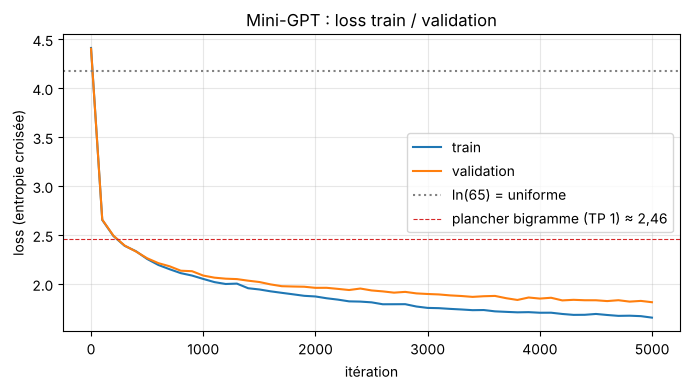

meilleure loss de validation : 1.8140 à l'itération 4999
valeurs finales : train 1.6566 | val 1.8140 | écart val - train = +0.1574
itération : train / val
    0 : 4.411 / 4.403
  500 : 2.256 / 2.263
 1000 : 2.052 / 2.086
 2000 : 1.873 / 1.961
 3000 : 1.756 / 1.898
 4000 : 1.706 / 1.851
 4999 : 1.657 / 1.814


In [13]:
# Tracé des pertes train / validation
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["it"], hist["train"], label="train")
ax.plot(hist["it"], hist["val"], label="validation")
ax.axhline(float(torch.log(torch.tensor(float(vocab_size)))), color="gray", ls=":", label="ln(65) = uniforme")
ax.axhline(2.455, color="tab:red", ls="--", lw=0.8, label="plancher bigramme (TP 1) ≈ 2,46")
ax.set_xlabel("itération"); ax.set_ylabel("loss (entropie croisée)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Mini-GPT : loss train / validation")
plt.tight_layout(); plt.show()

i_best = min(range(len(hist["val"])), key=lambda i: hist["val"][i])
print(f"meilleure loss de validation : {hist['val'][i_best]:.4f} à l'itération {hist['it'][i_best]}")
print(f"valeurs finales : train {hist['train'][-1]:.4f} | val {hist['val'][-1]:.4f} | écart val - train = {hist['val'][-1] - hist['train'][-1]:+.4f}")
print("itération : train / val")
for i in (0, 5, 10, 20, 30, 40, 50):
    j = min(i, len(hist["it"]) - 1); print(f"{hist['it'][j]:>5} : {hist['train'][j]:.3f} / {hist['val'][j]:.3f}")

**Réponses aux questions d'interprétation**

**Résultats (modèle de référence, 5 000 itérations, ≈ 4 min sur CPU).**

| Itération | loss train | loss val |
|---|---|---|
| 0 | 4,411 | 4,403 |
| 500 | 2,256 | 2,263 |
| 1 000 | 2,052 | 2,086 |
| 2 000 | 1,873 | 1,961 |
| 3 000 | 1,756 | 1,898 |
| 4 000 | 1,706 | 1,851 |
| **4 999** | **1,657** | **1,814** |

Les deux courbes **baissent de façon monotone**. La chute est très rapide au début (4,41 → 2,26 en 500 itérations), puis plus lente. La validation reste toujours au-dessus de l'entraînement, avec un écart qui passe de ≈ 0 à **+0,157** en fin d'entraînement ; la meilleure loss de validation est celle de la **dernière évaluation** (1,814) : elle baissait encore, donc le modèle n'avait pas fini d'apprendre. Pour situer : le meilleur bigramme du TP 1 plafonne à ≈ 2,48 en validation ; le mini-GPT descend à 1,81, soit −0,67 nat, **grâce au contexte** (jusqu'à 32 caractères).

**Pourquoi `model.eval()` puis `model.train()` ?** `eval()` désactive les comportements propres à l'entraînement (le **dropout** aléatoire) pour que la mesure soit déterministe et représentative ; `train()` les réactive pour la suite. Ici `dropout = 0.0` dans la configuration de base, donc la différence est nulle, mais l'habitude est essentielle dès que le dropout est actif (c'est le cas dans l'expérience à 0,2). `@torch.no_grad()` évite en outre de stocker le graphe de calcul.

**Si la loss d'entraînement baisse mais que la validation remonte ?** C'est du **surapprentissage** : le modèle mémorise des séquences du jeu d'entraînement au lieu de généraliser. Remèdes : arrêt anticipé (garder le modèle à la meilleure loss de validation), dropout / régularisation, plus de données, modèle plus petit. **Ce n'est pas le cas ici** : après 2,55 époques, la validation baisse encore (1,814 au minimum à la fin). L'écart de +0,157 est un écart de généralisation normal, pas encore un surapprentissage.

## Étape 9 — Générer 2 000 caractères après entraînement

In [14]:
context = torch.zeros(
    (1, 1), dtype=torch.long, device=device
)
torch.manual_seed(1337)
result = model.generate(context, max_new_tokens=2000)
apres = decode(result[0].tolist())
print(apres)


Canly hercedentanius lands nate we anone:
Go the beeing to Give stee; and yong
himself, you good sainmy mor behase
coll to Busino gin windess his poevery not;
Stides these getter myself
with pleasone out right shield high my hear
Ore book sellnsely.' Sing Pretue and the me:
I for lie taue how in tempt purtius:
They laster tongue the cLestit.

YORK:
Hese shall yikes me heart of me.

FRIAR MARGARET:
Piest me;
Without new accawd if commence if by me,
Are king prital not be'servel surpe kick give not.

LY AUMERLE:
To my baring name of soldiur of ormer's god,
Tell aling and sien all stild; lie and he soble morani, and sove when will enderain, in beseech fellow 'SBy lord,
Whose destenate-her not zolus,
For sourth.

FRolow Should within upon der.

VARLET:
Ay, will and do the the appelain ext low,
There'st see is unto to his your lieft lamence
That be use potless; or it these efore death?
I to nespigh our wite eyess,
Then my felposious she is your gation bloodin Ressenty:
Which lies his will 

In [15]:
# Comparaison avant / après : quelques statistiques simples sur les 2 000 caractères générés
import re
mots_vocab = set(re.findall(r"[A-Za-z']+", text))
def stats(s):
    mots = re.findall(r"[A-Za-z']+", s)
    return len(mots), sum(m in mots_vocab for m in mots) / max(1, len(mots)), s.count("\n"), s.count(":")
for nom, s in [("avant entraînement", avant), ("après entraînement", apres)]:
    nm, frac, nl, nc = stats(s)
    print(f"{nom:<19}: {nm:4d} mots | {100 * frac:5.1f} % de mots présents dans Shakespeare | {nl:3d} retours à la ligne | {nc:2d} « : »")
print("\nExtrait d'un vrai passage, pour comparaison :")
print(text[:200])

avant entraînement :  295 mots |   6.1 % de mots présents dans Shakespeare |  20 retours à la ligne | 25 « : »
après entraînement :  375 mots |  68.5 % de mots présents dans Shakespeare |  69 retours à la ligne | 17 « : »

Extrait d'un vrai passage, pour comparaison :
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


**Réponses aux questions d'interprétation**

**Pourquoi `@torch.no_grad()` ?** La génération n'entraîne rien : pas de rétropropagation, donc inutile de mémoriser le graphe de calcul. Sans lui, la mémoire croîtrait avec chaque nouveau caractère et le calcul serait plus lent. Les poids ne sont pas modifiés.

**Pourquoi `multinomial` plutôt que `argmax` ?** `argmax` est **déterministe** : il choisit toujours le caractère le plus probable, donc deux générations depuis le même contexte seraient identiques, et le texte tournerait vite en boucle de séquences très fréquentes (par exemple un même mot répété). `multinomial` échantillonne selon les probabilités apprises : un caractère à 70 % est choisi 70 % du temps, ce qui reproduit la **diversité de la distribution** du texte. C'est ce qui donne un texte varié (noms de locuteurs, vers, ponctuation) ; au prix de quelques fautes quand un caractère improbable est tiré.

**Comparaison avant / après** (2 000 caractères, même graine de génération) :
- **Avant** : suite de caractères au hasard (`jpzlYoSy;czdeL'YEiI…`), 6,1 % de « mots » présents dans le corpus, aucune structure.
- **Après** : **68,5 %** des mots générés existent dans Shakespeare (contre 6,1 %), 69 retours à la ligne (vers courts) et une mise en page de pièce de théâtre : noms de locuteurs en majuscules suivis de « : » (`YORK:`, `QUEEN MARGARET:`, `ROMEO:`, `DUKE OF AUMERLE:`), vers courts, ponctuation `; , . ?`, mots archaïques (`thou`, `thee`, `hence`, `lord`). Le modèle a donc appris l'orthographe locale, le rythme des vers et le format des répliques.
- **Limites** : beaucoup de mots inventés (`accawd`, `yikes`, `moranis`), phrases sans sens, personnages mélangés. Le modèle (0,21 M paramètres, 32 caractères de contexte, 5 000 itérations) ne comprend pas le sens ; la consigne n'exige d'ailleurs pas un anglais correct. Le nombre de « : » (17 contre 25 avant) ne signifie rien : avant entraînement, c'est le hasard qui les place.

### Expériences : `block_size`, nombre de têtes, dropout

Une fonction `experience` reconstruit les classes avec d'autres hyperparamètres globaux (les classes lisent `block_size`, `n_head`, `dropout`, … au moment de la création), entraîne puis mesure la loss finale sur 200 mini-batchs.

**Budget réduit** : 3 000 itérations (au lieu de 5 000) et **2 graines** par configuration, pour tenir en CPU. La configuration de base est rejouée dans les mêmes conditions pour une comparaison équitable. Avec seulement 2 graines, des écarts de quelques centièmes ne sont pas concluants.

In [16]:
BASE = dict(block_size=32, n_embd=64, n_head=4, n_layer=4, dropout=0.0, batch_size=16)

@torch.no_grad()
def evaluer(m, n_batches=200):
    m.eval(); out = {}
    for split in ("train", "val"):
        out[split] = torch.stack([m(*get_batch(split))[1] for _ in range(n_batches)]).mean().item()
    m.train(); return out

def experience(iters=3000, seed=1337, **over):
    cfg = {**BASE, **over}
    old = {k: globals()[k] for k in cfg}
    globals().update(cfg)
    try:
        torch.manual_seed(seed)
        m = BigramLanguageModel().to(device)
        opt = torch.optim.AdamW(m.parameters(), lr=learning_rate)
        for _ in range(iters):
            xb, yb = get_batch("train")
            _, l = m(xb, yb)
            opt.zero_grad(set_to_none=True); l.backward(); opt.step()
        res = evaluer(m); res["params"] = count(m)
        res["texte"] = generer(m, 300, seed=1337) if seed == 1337 else None
        return res
    finally:
        globals().update(old)

CONFIGS = [
    ("base : block 32, 4 têtes, dropout 0",   {}),
    ("block_size = 16",                       dict(block_size=16)),
    ("block_size = 64",                       dict(block_size=64)),
    ("1 tête (d_h = 64)",                     dict(n_head=1)),
    ("dropout = 0,2",                         dict(dropout=0.2)),
]
resultats = {}
t0 = time.time()
for nom, over in CONFIGS:
    resultats[nom] = [experience(seed=s, **over) for s in (1337, 1338)]
    print(f"{nom:<40} terminé ({time.time() - t0:5.0f} s)")

base : block 32, 4 têtes, dropout 0      terminé (  149 s)


block_size = 16                          terminé (  269 s)


block_size = 64                          terminé (  476 s)


1 tête (d_h = 64)                        terminé (  570 s)


dropout = 0,2                            terminé (  776 s)


In [17]:
import statistics as st
print(f"{'configuration':<40}| {'params':>8} | {'train (2 graines)':>20} | {'val (2 graines)':>20} | val moyenne | écart val-train")
for nom, runs in resultats.items():
    tr = [r["train"] for r in runs]; va = [r["val"] for r in runs]
    print(f"{nom:<40}| {runs[0]['params']:>8,} | {tr[0]:9.3f} {tr[1]:9.3f} | {va[0]:9.3f} {va[1]:9.3f} | {st.mean(va):11.3f} | {st.mean(va) - st.mean(tr):+.3f}")

configuration                           |   params |    train (2 graines) |      val (2 graines) | val moyenne | écart val-train
base : block 32, 4 têtes, dropout 0     |  209,729 |     1.769     1.753 |     1.887     1.901 |       1.894 | +0.133
block_size = 16                         |  208,705 |     1.843     1.848 |     1.977     1.977 |       1.977 | +0.131
block_size = 64                         |  211,777 |     1.695     1.694 |     1.844     1.855 |       1.850 | +0.155
1 tête (d_h = 64)                       |  209,729 |     1.753     1.741 |     1.891     1.894 |       1.892 | +0.146
dropout = 0,2                           |  209,729 |     1.876     1.876 |     1.963     1.975 |       1.969 | +0.093


In [18]:
# Un extrait de 300 caractères par configuration (graine d'entraînement 1337, génération graine 1337)
for nom, runs in resultats.items():
    print("-----", nom, "-----")
    print(runs[0]["texte"][:300].replace("\n", "\n"))
    print()

----- base : block 32, 4 têtes, dropout 0 -----

Carlood the enew in, lazes nage we profs:
Whe thile have bic wits to abeaty.

Thiss I self; gentle, coyfuld behas your and But to grace.

RAETIS:
You hather if this fate
We trunchmes hat is graste I so hart thoses he hand my hear
Ofe boests gnnot blaigg hast the puchilf
A gill. Shal woal for will.


----- block_size = 16 -----

COMEYS: the eneace in roling heave anone: ane this powity in with this bake nownimss to your apaliancey more shallocks: tha'll to greath your hady fevery now; it dead
Well, to tany; fetterse pleatook it brittloses he dancim, your by incestell. Lencl's givest't poince, firs:
I for ly word for the te

----- block_size = 64 -----

Cirstan thee;
'TEin, lazEsCisher a procted teat,-body is bid with tei,
They nothims cold all agare,
Thy morther sooce landa's of frone no deliking
This annow; if yea should trusan'd untrait: proughtesitior;
And bie me now my hand hith; eatelly;
And 'begnt Pletty affulty megily.
Shall I use 

**Réponses aux questions d'interprétation**

**Protocole.** 3 000 itérations (au lieu de 5 000), 2 graines (1337, 1338), loss mesurée sur 200 batchs. La base rejouée dans ce protocole donne val 1,887 / 1,901 (moyenne 1,894) : **l'écart entre graines est de ≈ 0,014**. Toute différence de cet ordre est donc du bruit ; avec seulement 2 graines, ces résultats sont indicatifs et non des preuves.

| Configuration | Paramètres | val moyenne | écart val − train |
|---|---|---|---|
| base (block 32, 4 têtes, dropout 0) | 209 729 | **1,894** | +0,133 |
| `block_size = 16` | 208 705 | 1,977 | +0,131 |
| `block_size = 64` | 211 777 | **1,850** | +0,155 |
| 1 tête ($d_h = 64$) | 209 729 | 1,892 | +0,146 |
| dropout = 0,2 | 209 729 | 1,969 | +0,093 |

**1. `block_size`.** La loss de validation **baisse quand le contexte augmente** : 1,977 (16) → 1,894 (32) → 1,850 (64). Les deux écarts (−0,08 puis −0,04) dépassent l'écart entre graines (0,014) : un contexte plus long aide, car chaque position peut s'appuyer sur davantage de caractères, avec des gains décroissants. Le coût est réel : temps total pour les 2 graines : 120 s (16) et 207 s (64) contre 149 s pour la base (surtout dû à $T^2$ dans l'attention), et le texte obtenu avec 16 est visiblement plus approximatif. Les paramètres ne varient presque pas (seule la table de positions change : 1 024, 2 048, 4 096 poids).

**2. Une tête contre quatre** (à $n_{emb} = 64$ constant, donc même nombre de paramètres : 209 729). Résultat : **1,892 contre 1,894, aucune différence mesurable** (inférieure à l'écart entre graines). À cette échelle et avec ce budget, la multiplicité des têtes n'apporte rien de mesurable. On ne peut pas en conclure qu'elle est inutile en général : l'argument théorique reste que plusieurs têtes peuvent suivre en parallèle des relations différentes (voir le caractère précédent, le début du mot, la ponctuation…), mais ce test ne permet pas de le montrer.

**3. Dropout.** Il n'y a pas de surapprentissage à corriger ici (la validation baisse encore). Avec dropout = 0,2 : l'écart val − train diminue (+0,093 contre +0,133), mais la validation est **plus mauvaise** (1,969 contre 1,894) : le modèle est déjà plutôt *sous-entraîné* que sur-entraîné, et le dropout ralentit l'apprentissage. Ce serait utile avec un modèle plus grand, plus longtemps entraîné, ou sur un corpus plus petit.

**Limite** : budget réduit (3 000 itérations), 2 graines, un seul réglage par expérience ; les différences inférieures à ≈ 0,03 sont à considérer comme du bruit.

## Bilan des quatre TP

**Bilan des quatre TP — réponses**

**Tableau de correspondance.**

| Classe / brique | Notion du cours | Forme in → out |
|---|---|---|
| `encode` / `decode`, `stoi` / `itos` (TP 1) | tokenisation (ici : caractère) | texte ↔ entiers |
| `get_batch` (TP 1) | exemples $(x, y)$ décalés d'une position | → `(B, T)` |
| `token_embedding_table` | embedding de token | `(B,T)` → `(B,T,C)` |
| `position_embedding_table` | embedding de position | `(T,)` → `(T,C)` |
| `Head` (TP 2) | auto-attention causale ($q$, $k$, $v$) | `(B,T,C)` → `(B,T,d_h)` |
| `MultiHeadAttention` | têtes en parallèle + projection $W_O$ | `(B,T,C)` → `(B,T,C)` |
| `LayerNorm` (TP 3) | normalisation par token | `(B,T,C)` → `(B,T,C)` |
| `FeedForward` (TP 3) | MLP `C → 4C → C` par position | `(B,T,C)` → `(B,T,C)` |
| `Block` | pré-norm + résiduels | `(B,T,C)` → `(B,T,C)` |
| `lm_head` | unembedding | `(B,T,C)` → `(B,T,vocab)` |
| `F.cross_entropy` | loss d'entropie croisée / softmax | logits → scalaire |
| `generate` | échantillonnage autorégressif | `(B,T)` → `(B,T+n)` |

**Quelle brique crée le contexte ?** L'**attention** (`Head` / `MultiHeadAttention`) : c'est la seule qui fait circuler l'information *entre* positions. Les embeddings de position lui donnent la notion d'ordre, et le masque triangulaire lui impose la causalité (sans lui, le futur fuiterait : TP 2). **Laquelle transforme un token ?** Le **MLP** (`FeedForward`), appliqué à chaque position indépendamment (TP 3 : modifier le token 5 ne change que la sortie 5). **Laquelle produit les logits ?** `lm_head`, qui projette le vecteur contextualisé `(B,T,64)` vers `(B,T,65)` ; leur softmax donne la distribution du caractère suivant. **Où la loss agit-elle ?** Elle est calculée à la sortie sur les $B \cdot T$ prédictions, puis le gradient traverse *tout* le modèle : `lm_head`, `ln_f`, les 4 blocs (y compris les chemins résiduels, qui l'acheminent sans l'atténuer), les deux embeddings. Les 209 729 paramètres sont mis à jour par `AdamW`.

**Ce que l'on a gagné de TP en TP** (loss de validation, entropie croisée en nats par caractère) : uniforme 4,17 → bigramme (un seul caractère de contexte) ≈ 2,48 → mini-GPT 1,81 (jusqu'à 32 caractères de contexte). Les trois ajouts qui font passer du bigramme au Transformer sont : l'attention (contexte), le MLP (calcul) et les résiduels + LayerNorm (profondeur trainable).